# Proyecto RappiPlus: de datos a decisiones de negocio

**Introducción**


El objetivo de este proyecto es evaluar el desempeño del servicio **RappiPlus** para apoyar **decisiones de negocio basadas en datos**.

Se trabajan con múltiples datasets del negocio:

- **rappiplus_orders_raw.csv** → información de pedidos, precios, descuentos y revenue  
- **rappiplus_catalog.csv** → costos de productos, categorías y proveedores  
- **rappiplus_marketing_spend.csv** → inversión en marketing por canal y país  
- **events / users / user_activity (SQL)** → comportamiento del usuario dentro de la plataforma  
- **experiment_checkout_ui.csv** → resultados de un experimento A/B en el checkout  

El análisis sigue una lógica clara y progresiva:

1. 🔍 Evaluar si podemos confiar en los datos (calidad de datos en Python) 

2. 💰 Analizar si el negocio es rentable (revenue, costos y profit)  

3. 🛒 Entender dónde se pierden los usuarios (funnel de conversión)  

4. 🔁 Evaluar si los usuarios regresan (retención por cohortes)  

5. 🧪 Validar si los cambios generan impacto (test estadístico)  

6. 📊 Comunicar los resultados (dashboard en BI)  

A lo largo del proyecto, se transforman datos en insights para responder preguntas clave del negocio y proponer **recomendaciones accionables**.

---

## 🔹 Paso 1: Cargar y validar la calidad de los datos

---

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:** Familiarizarte con la estructura de los datasets del negocio antes de analizarlos.

**Instrucciones:**

- Importa las librerías necesarias
- Carga los archivos:
  - `rappiplus_orders_raw.csv`
  - `rappiplus_catalog.csv`
  - `rappiplus_marketing_spend.csv`
- Guarda los DataFrames en:
  - `orders`, `catalog`, `marketing`
- Explora cada dataset.

---

In [2]:
# importar librerías
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep, proportion_effectsize
from statsmodels.stats.power import NormalIndPower

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

estilo visual y funciones de apoyo.** Se define una paleta única (accesible para daltonismo) y funciones reutilizables para que todas las gráficas del proyecto se lean como un solo sistema: mismo color = misma entidad, rojo solo para pérdidas y verde solo para ganancias.

In [3]:
#  paleta y estilo común para todas las gráficas
AZUL, NARANJA, AQUA, AMARILLO = '#257de0', '#f47230', '#00b894', '#f2a600'
VERDE, ROJO, GRIS = '#0aac23', '#dc3c3d', '#b8b8b8'
TEXTO, TEXTO_2 = '#191919', '#666666'
PALETA = [AZUL, NARANJA, AQUA, AMARILLO, '#ee7fac', '#008a17', '#6a4ce2', '#ec4647']
CMAP_AZUL = LinearSegmentedColormap.from_list('azul', ['#eaf3fe', '#84b9f3', '#257de0', '#0e3d7e'])
CMAP_DIV = LinearSegmentedColormap.from_list('div', ['#dc3c3d', '#f6c9c9', '#efefef', '#b6d5f8', '#1757ac'])

plt.rcParams.update({
    'figure.figsize': (10, 4.5), 'figure.dpi': 100,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#cfcfcf', 'axes.linewidth': 0.8,
    'axes.grid': True, 'grid.color': '#ececec', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.labelcolor': TEXTO_2,
    'xtick.color': TEXTO_2, 'ytick.color': TEXTO_2, 'text.color': TEXTO,
    'axes.prop_cycle': plt.cycler(color=PALETA), 'legend.frameon': False, 'font.size': 10.5,
})

def dinero(x, pos=None):
    '''Formato compacto de dinero: $1.2M, $350K, −$95'''
    signo = '−' if x < 0 else ''
    x = abs(x)
    if x >= 1e6:
        return f'{signo}${x/1e6:,.2f}M'
    if x >= 1e3:
        return f'{signo}${x/1e3:,.0f}K'
    return f'{signo}${x:,.0f}'

def etiquetar_barras(ax, barras, valores, fmt, horizontal=False, size=9):
    '''Etiqueta cada barra con su valor (compatible con matplotlib 3.3)'''
    for b, v in zip(barras, valores):
        if horizontal:
            x, y = b.get_x() + b.get_width(), b.get_y() + b.get_height() / 2
            ax.annotate(fmt(v), (x, y), xytext=(4 if v >= 0 else -4, 0), textcoords='offset points',
                        ha='left' if v >= 0 else 'right', va='center', fontsize=size, color=TEXTO_2)
        else:
            x, y = b.get_x() + b.get_width() / 2, b.get_y() + b.get_height()
            ax.annotate(fmt(v), (x, y), xytext=(0, 3 if v >= 0 else -12), textcoords='offset points',
                        ha='center', fontsize=size, color=TEXTO_2)

def titulo(ax, texto, subtitulo=None):
    '''Título alineado a la izquierda + subtítulo con la lectura clave ($ escapado para matplotlib)'''
    ax.set_title(texto.replace('$', r'\$'), loc='left', pad=22 if subtitulo else 8)
    if subtitulo:
        ax.text(0, 1.02, subtitulo.replace('$', r'\$'), transform=ax.transAxes, fontsize=9.5, color=TEXTO_2, va='bottom')

def perfil(df):
    '''➕ Perfil de calidad por columna: tipo, nulos, % nulos y valores únicos'''
    return pd.DataFrame({'tipo': df.dtypes.astype(str),
                         'nulos': df.isna().sum(),
                         '% nulos': (df.isna().mean() * 100).round(2),
                         'valores únicos': df.nunique()})

In [4]:
# cargar archivos
orders = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_orders_raw.csv')
catalog = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_catalog.csv')
marketing = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_marketing_spend.csv')

# copia del dato crudo para medir el impacto de la limpieza al final
orders_raw = orders.copy()

for nombre, df in [('orders', orders), ('catalog', catalog), ('marketing', marketing)]:
    print(f'{nombre:<10} → {df.shape[0]:>6,} filas x {df.shape[1]} columnas')

orders     → 25,100 filas x 12 columnas
catalog    →      7 filas x 4 columnas
marketing  →  1,620 filas x 5 columnas


In [5]:
# explorar datasets
for nombre, df in [('orders', orders), ('catalog', catalog), ('marketing', marketing)]:
    print('=' * 100)
    print(f'{nombre.upper()} | duplicados exactos: {df.duplicated().sum()}')
    print('=' * 100)
    display(df.head())
    display(perfil(df))

ORDERS | duplicados exactos: 100


,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.00,332.69,0.00,665.37
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.00,176.86,5.00,171.86
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.00,102.99,10.00,195.99
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.00,257.87,15.00,242.87
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.00,336.28,0.00,336.28


,tipo,nulos,% nulos,valores únicos
id_pedido,object,0,0.00,25000
id_usuario,object,0,0.00,7642
fecha_hora_pedido,object,0,0.00,181
pais,object,300,1.20,6
dispositivo,object,20,0.08,2
fuente_referencia,object,30,0.12,3
nombre_producto,object,30,0.12,7
categoria_producto,object,80,0.32,3
cantidad,float64,50,0.20,6
precio_unitario,float64,50,0.20,19543


CATALOG | duplicados exactos: 0


,nombre_producto,categoria_producto,costo_unitario,proveedor
0,Laptop-Gaming-16GB,Electrónica,280.68,"Fuller, Pena and Myers"
1,Phone-Pro-128GB,Electrónica,10.12,King Ltd
2,Tablet-Standard-64GB,Electrónica,25.21,Bowers LLC
3,Blender-XL-Red,Hogar,176.64,Long-Reid
4,Vacuum-Pro-Black,Hogar,16.60,"Rivera, Carr and Finley"


,tipo,nulos,% nulos,valores únicos
nombre_producto,object,0,0.00,7
categoria_producto,object,0,0.00,3
costo_unitario,float64,0,0.00,7
proveedor,object,0,0.00,7


MARKETING | duplicados exactos: 0


,fecha,pais,id_campaña,canal,gasto
0,2025-01-01,Mexico,organic_Mexico,organic,"2,446.25"
1,2025-01-01,Mexico,paid_search_Mexico,paid_search,"2,704.34"
2,2025-01-01,Mexico,social_Mexico,social,"2,045.01"
3,2025-01-01,Colombia,organic_Colombia,organic,"2,597.21"
4,2025-01-01,Colombia,paid_search_Colombia,paid_search,"1,771.40"


,tipo,nulos,% nulos,valores únicos
fecha,object,0,0.00,180
pais,object,0,0.00,3
id_campaña,object,0,0.00,9
canal,object,101,6.23,3
gasto,float64,0,0.00,1612


In [6]:
# estadísticos de las variables numéricas (detecta negativos, ceros y valores extremos)
display(orders.describe().T)
display(marketing.describe().T)
display(catalog)

,count,mean,std,min,25%,50%,75%,max
cantidad,"25,050.00",7.09,296.28,-2.00,1.00,2.00,2.00,"20,000.00"
precio_unitario,"25,050.00",259.31,138.73,20.03,138.38,258.72,380.33,499.96
monto_descuento,"25,050.00",4.50,5.22,0.00,0.00,0.00,10.00,15.00
monto_total,"25,100.00","2,072.68","98,949.95",-492.65,180.51,341.75,518.58,"8,840,200.00"


,count,mean,std,min,25%,50%,75%,max
gasto,"1,620.00","1,772.74",734.43,501.11,"1,128.03","1,782.42","2,420.68","2,999.36"


,nombre_producto,categoria_producto,costo_unitario,proveedor
0,Laptop-Gaming-16GB,Electrónica,280.68,"Fuller, Pena and Myers"
1,Phone-Pro-128GB,Electrónica,10.12,King Ltd
2,Tablet-Standard-64GB,Electrónica,25.21,Bowers LLC
3,Blender-XL-Red,Hogar,176.64,Long-Reid
4,Vacuum-Pro-Black,Hogar,16.60,"Rivera, Carr and Finley"
5,Sneakers-Urban-42,Moda,17.21,Greene-Smith
6,Jacket-Winter-M,Moda,189.31,Mcmillan-Rhodes


In [7]:
#  valores de las variables categóricas (detecta errores de escritura y categorías inconsistentes)
for col in ['pais', 'dispositivo', 'fuente_referencia', 'nombre_producto', 'categoria_producto']:
    print(f'{col}:', orders[col].value_counts(dropna=False).to_dict())
print()
print('catalog.categoria_producto:', catalog['categoria_producto'].unique().tolist())
print('marketing.canal:', marketing['canal'].value_counts(dropna=False).to_dict())
print()
print('Rango de fechas orders   :', orders['fecha_hora_pedido'].min(), '→', orders['fecha_hora_pedido'].max())
print('Rango de fechas marketing:', marketing['fecha'].min(), '→', marketing['fecha'].max())

pais: {'Colombia': 7520, 'Mexico': 7502, 'Argentina': 7291, 'mexico': 865, 'colombia': 823, 'argentina': 799, nan: 300}
dispositivo: {'desktop': 12759, 'mobile': 12321, nan: 20}
fuente_referencia: {'social': 8428, 'organic': 8329, 'paid_search': 8313, nan: 30}
nombre_producto: {'Vacuum-Pro-Black': 4199, 'Blender-XL-Red': 4195, 'Jacket-Winter-M': 4192, 'Sneakers-Urban-42': 4160, 'Laptop-Gaming-16GB': 2794, 'Tablet-Standard-64GB': 2780, 'Phone-Pro-128GB': 2750, nan: 30}
categoria_producto: {'Hogar': 8385, 'Moda': 8323, 'Electronica': 8312, nan: 80}

catalog.categoria_producto: ['Electrónica', 'Hogar', 'Moda']
marketing.canal: {'paid_search': 507, 'organic': 506, 'social': 506, nan: 101}

Rango de fechas orders   : 2025-01-01 → 2025-06-30
Rango de fechas marketing: 2025-01-01 → 2025-06-29


**🔎 Hallazgos de la exploración inicial**

| Dataset | Problema detectado | Impacto si no se corrige |
|---|---|---|
| orders | 100 filas duplicadas (mismo `id_pedido` y mismos valores) | Infla revenue y número de pedidos |
| orders | `pais` con mayúsculas inconsistentes (`mexico`, `colombia`, `argentina`: 2,487 filas) y 300 nulos | Los países aparecen duplicados en cualquier agrupación |
| orders | `categoria_producto` escrita `Electronica` (en el catálogo es `Electrónica`) y 80 nulos | El cruce con el catálogo por categoría falla |
| orders | 30 pedidos sin `nombre_producto` | No se puede asignar costo |
| orders | 50 pedidos sin `cantidad`, `precio_unitario` ni `monto_descuento` (siempre las tres a la vez) | No se puede calcular costo ni validar el monto |
| orders | `cantidad` negativa (4 pedidos) y extrema (10,000 y 20,000 unidades en 10 pedidos) | Un solo pedido llega a $8.8M y distorsiona todos los KPIs |
| orders | fechas como texto; nulos en `dispositivo` (20) y `fuente_referencia` (30) | Impide análisis temporal y segmentación |
| marketing | 101 nulos en `canal` y fechas como texto | El gasto por canal queda incompleto |
| catalog | Sin problemas: 7 productos únicos, costos positivos | — |

---

### Revisión y calidad de datos

**🎯 Objetivo:** Detectar y corregir problemas en los datos que puedan afectar el análisis de revenue, costos y rentabilidad.

Se revisan los 3 datasets
- Validar y convertir fechas al formato correcto  
- Revisar variables numéricas (sin negativos o ceros inválidos)  
- Verificar consistencia de montos  
- Eliminar duplicados  
- Revisar variables categóricas 

---

In [8]:
# ORDERS · 1) Duplicados
ids_repetidos = orders[orders['id_pedido'].duplicated(keep=False)]
print('Duplicados exactos             :', orders.duplicated().sum())
print('id_pedido repetidos            :', orders['id_pedido'].duplicated().sum())
print('¿Los id repetidos son copias idénticas?', ids_repetidos.duplicated(keep=False).all())

bitacora = [('Datos crudos', len(orders), orders['monto_total'].sum())]  # ➕ bitácora de limpieza
orders = orders.drop_duplicates().reset_index(drop=True)
bitacora.append(('Eliminar duplicados exactos', len(orders), orders['monto_total'].sum()))
print('Filas después de quitar duplicados:', len(orders))

Duplicados exactos             : 100
id_pedido repetidos            : 100
¿Los id repetidos son copias idénticas? True
Filas después de quitar duplicados: 25000


In [9]:
# ORDERS · 2) Fechas al formato correcto
orders['fecha_hora_pedido'] = pd.to_datetime(orders['fecha_hora_pedido'], format='%Y-%m-%d', errors='coerce')
print('Fechas no convertibles:', orders['fecha_hora_pedido'].isna().sum())
print('Rango:', orders['fecha_hora_pedido'].min().date(), '→', orders['fecha_hora_pedido'].max().date(),
      f"({orders['fecha_hora_pedido'].dt.date.nunique()} días)")

Fechas no convertibles: 0
Rango: 2025-01-01 → 2025-06-30 (181 días)


In [10]:
# ORDERS · 3) Variables categóricas
# país: quitar espacios y unificar mayúsculas (mexico → Mexico)
orders['pais'] = orders['pais'].str.strip().str.title()

# ➕ Validación: ¿un usuario compra siempre desde el mismo país y el mismo dispositivo?
paises_x_usuario = orders.dropna(subset=['pais']).groupby('id_usuario')['pais'].nunique()
disp_x_usuario = orders.dropna(subset=['dispositivo']).groupby('id_usuario')['dispositivo'].nunique()
fuentes_x_usuario = orders.dropna(subset=['fuente_referencia']).groupby('id_usuario')['fuente_referencia'].nunique()
print('Usuarios con más de un país       :', (paises_x_usuario > 1).sum(), 'de', len(paises_x_usuario))
print('Usuarios con más de un dispositivo:', (disp_x_usuario > 1).sum(), 'de', len(disp_x_usuario))
print('Usuarios con más de una fuente    :', (fuentes_x_usuario > 1).sum(), 'de', len(fuentes_x_usuario))

Usuarios con más de un país       : 0 de 7624
Usuarios con más de un dispositivo: 0 de 7640
Usuarios con más de una fuente    : 5710 de 7642


➕ **Imputación con el historial del usuario.** País y dispositivo son atributos *del usuario* (ningún usuario tiene más de uno), así que un nulo se puede recuperar con certeza a partir de sus otros pedidos. En cambio, `fuente_referencia` cambia entre pedidos del mismo usuario, por lo que sus nulos se marcan como `desconocido` en lugar de inventar un valor.

In [11]:
def imputar_por_usuario(df, col):
    '''➕ Completa nulos con el valor que el mismo usuario tiene en sus otros pedidos'''
    valor_usuario = df.dropna(subset=[col]).groupby('id_usuario')[col].agg(lambda s: s.mode().iat[0])
    nulos_antes = df[col].isna().sum()
    df[col] = df[col].fillna(df['id_usuario'].map(valor_usuario))
    print(f'{col:<12}: {nulos_antes} nulos → {nulos_antes - df[col].isna().sum()} recuperados con el historial del usuario,'
          f' {df[col].isna().sum()} sin historial')
    return df

orders = imputar_por_usuario(orders, 'pais')
orders = imputar_por_usuario(orders, 'dispositivo')

# los que no tienen historial y la fuente de referencia se etiquetan explícitamente
orders['pais'] = orders['pais'].fillna('Desconocido')
orders['dispositivo'] = orders['dispositivo'].fillna('desconocido')
orders['fuente_referencia'] = orders['fuente_referencia'].fillna('desconocido')

# categoría: unificar con el catálogo (Electronica → Electrónica) y completar nulos desde el producto
mapa_categoria = catalog.set_index('nombre_producto')['categoria_producto']
orders['categoria_producto'] = orders['categoria_producto'].str.strip().replace({'Electronica': 'Electrónica'})
nulos_cat = orders['categoria_producto'].isna().sum()
orders['categoria_producto'] = orders['categoria_producto'].fillna(orders['nombre_producto'].map(mapa_categoria))
print(f'categoria   : {nulos_cat} nulos → {nulos_cat - orders["categoria_producto"].isna().sum()} completados con el catálogo')

# ➕ coherencia producto–categoría contra el catálogo
incoherentes = orders['nombre_producto'].notna() & (orders['nombre_producto'].map(mapa_categoria) != orders['categoria_producto'])
print('Pedidos con categoría distinta a la del catálogo:', incoherentes.sum())
print()
for col in ['pais', 'dispositivo', 'fuente_referencia', 'categoria_producto']:
    print(f'{col}:', orders[col].value_counts(dropna=False).to_dict())

pais        : 300 nulos → 281 recuperados con el historial del usuario, 19 sin historial
dispositivo : 20 nulos → 18 recuperados con el historial del usuario, 2 sin historial
categoria   : 80 nulos → 50 completados con el catálogo
Pedidos con categoría distinta a la del catálogo: 0

pais: {'Mexico': 8440, 'Colombia': 8386, 'Argentina': 8155, 'Desconocido': 19}
dispositivo: {'desktop': 12721, 'mobile': 12277, 'desconocido': 2}
fuente_referencia: {'social': 8402, 'organic': 8288, 'paid_search': 8280, 'desconocido': 30}
categoria_producto: {'Hogar': 8355, 'Moda': 8324, 'Electrónica': 8291, nan: 30}


In [12]:
# ORDERS · 4) Variables numéricas
num_cols = ['cantidad', 'precio_unitario', 'monto_descuento', 'monto_total']
display(orders[num_cols].describe().T)
print('¿Los nulos numéricos están en las mismas filas?')
print(orders[['cantidad', 'precio_unitario', 'monto_descuento']].isna().value_counts())
print()
print('Valores de cantidad:', orders['cantidad'].value_counts(dropna=False).sort_index().to_dict())
print('Valores de descuento:', orders['monto_descuento'].value_counts(dropna=False).sort_index().to_dict())

,count,mean,std,min,25%,50%,75%,max
cantidad,"24,950.00",7.12,296.87,-2.00,1.00,2.00,2.00,"20,000.00"
precio_unitario,"24,950.00",259.37,138.69,20.03,138.47,258.80,380.38,499.96
monto_descuento,"24,950.00",4.50,5.22,0.00,0.00,0.00,10.00,15.00
monto_total,"25,000.00","2,079.50","99,147.60",-492.65,180.67,341.80,518.58,"8,840,200.00"


¿Los nulos numéricos están en las mismas filas?
cantidad  precio_unitario  monto_descuento
False     False            False              24950
True      True             True                  50
dtype: int64

Valores de cantidad: {-2.0: 1, -1.0: 3, 1.0: 12345, 2.0: 12591, 10000.0: 6, 20000.0: 4, nan: 50}
Valores de descuento: {0.0: 12498, 5.0: 4920, 10.0: 5048, 15.0: 2484, nan: 50}


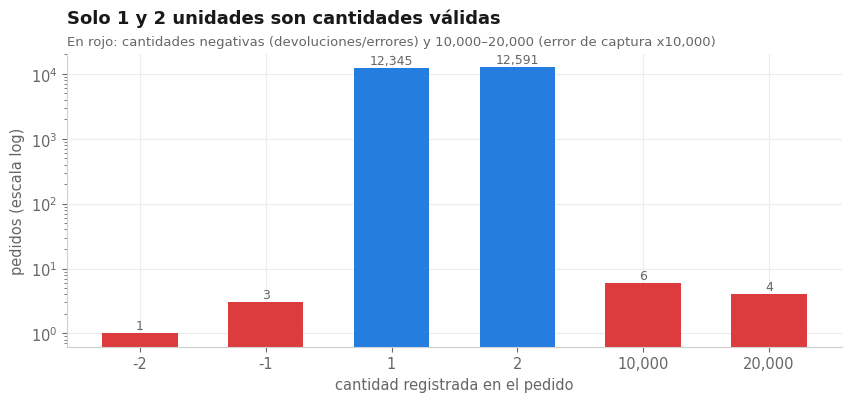

In [13]:
# visualizar los valores inválidos de cantidad (escala logarítmica)
conteo_cant = orders['cantidad'].value_counts().sort_index()
colores = [ROJO if (c <= 0 or c > 100) else AZUL for c in conteo_cant.index]
fig, ax = plt.subplots(figsize=(10, 3.8))
barras = ax.bar([f'{c:,.0f}' for c in conteo_cant.index], conteo_cant.values, color=colores, width=0.6)
etiquetar_barras(ax, barras, conteo_cant.values, lambda v: f'{v:,.0f}')
ax.set_yscale('log')
ax.set_xlabel('cantidad registrada en el pedido')
ax.set_ylabel('pedidos (escala log)')
titulo(ax, 'Solo 1 y 2 unidades son cantidades válidas',
       'En rojo: cantidades negativas (devoluciones/errores) y 10,000–20,000 (error de captura x10,000)')
plt.show()

In [14]:
# Reglas de eliminación (cada regla se cuantifica antes de aplicarla)
reglas = {
    'Sin nombre de producto (no hay costo)': orders['nombre_producto'].isna(),
    'Sin cantidad / precio / descuento': orders[['cantidad', 'precio_unitario', 'monto_descuento']].isna().any(axis=1),
    'Cantidad negativa o cero': orders['cantidad'] <= 0,
    'Cantidad atípica (≥ 10,000 unidades)': orders['cantidad'] > 100,
}
resumen_reglas = pd.DataFrame({
    'pedidos': {k: v.sum() for k, v in reglas.items()},
    'monto_total afectado': {k: orders.loc[v, 'monto_total'].sum() for k, v in reglas.items()},
})
resumen_reglas['% de pedidos'] = resumen_reglas['pedidos'] / len(orders) * 100
display(resumen_reglas)

for nombre_regla, mascara in reglas.items():
    orders = orders[~mascara.reindex(orders.index, fill_value=False)]
    bitacora.append((nombre_regla, len(orders), orders['monto_total'].sum()))
orders = orders.reset_index(drop=True)
orders['cantidad'] = orders['cantidad'].astype(int)
print('Pedidos restantes:', len(orders))

,pedidos,monto_total afectado,% de pedidos
Sin nombre de producto (no hay costo),30,"12,262.62",0.12
Sin cantidad / precio / descuento,50,"21,628.00",0.20
Cantidad negativa o cero,4,"-1,147.30",0.02
"Cantidad atípica (≥ 10,000 unidades)",10,"42,344,700.00",0.04


Pedidos restantes: 24906


📝 **Decisión sobre los valores atípicos.** Las cantidades de 10,000 y 20,000 son exactamente 1 y 2 multiplicadas por 10,000, lo que sugiere un error de captura de unidades. Aunque se podrían "corregir" dividiendo entre 10,000, no hay forma de confirmarlo, así que se eliminan: son 10 pedidos (0.04 %) y, sin ellos, el revenue real cambia menos de 0.1 %. Lo mismo aplica a las cantidades negativas (posibles devoluciones mal registradas).

In [15]:
# ORDERS · 5) Consistencia de montos: monto_total = cantidad × precio_unitario − monto_descuento
subtotal = orders['cantidad'] * orders['precio_unitario']
diferencia = (orders['monto_total'] - (subtotal - orders['monto_descuento'])).abs()
print(f'Pedidos con diferencia > $0.01 : {(diferencia > 0.011).sum()}')
print(f'Diferencia máxima              : ${diferencia.max():.4f}  (redondeo a centavos)')
print(f'Descuento mayor que el subtotal: {(orders["monto_descuento"] > subtotal).sum()}')
print(f'Montos totales <= 0            : {(orders["monto_total"] <= 0).sum()}')
print(f'Precios fuera de rango (<= 0)  : {(orders["precio_unitario"] <= 0).sum()}')
print()
print('Nulos restantes en orders:', orders.isna().sum().sum(), '| duplicados:', orders.duplicated().sum(),
      '| id_pedido únicos:', orders['id_pedido'].is_unique)
orders.info()

Pedidos con diferencia > $0.01 : 0
Diferencia máxima              : $0.0100  (redondeo a centavos)
Descuento mayor que el subtotal: 0
Montos totales <= 0            : 0
Precios fuera de rango (<= 0)  : 0

Nulos restantes en orders: 0 | duplicados: 0 | id_pedido únicos: True
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24906 entries, 0 to 24905
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_pedido           24906 non-null  object        
 1   id_usuario          24906 non-null  object        
 2   fecha_hora_pedido   24906 non-null  datetime64[ns]
 3   pais                24906 non-null  object        
 4   dispositivo         24906 non-null  object        
 5   fuente_referencia   24906 non-null  object        
 6   nombre_producto     24906 non-null  object        
 7   categoria_producto  24906 non-null  object        
 8   cantidad            24906 non-null  int64         


In [16]:
#  bitácora de limpieza — cuántos pedidos y cuánto revenue se removió en cada paso
bit = pd.DataFrame(bitacora, columns=['paso', 'filas', 'monto_total'])
bit['filas removidas'] = (-bit['filas'].diff()).fillna(0).astype(int)
bit['monto removido'] = (-bit['monto_total'].diff()).fillna(0)
display(bit)
pct_filas = (1 - len(orders) / len(orders_raw)) * 100
print(f'Total removido: {len(orders_raw) - len(orders)} filas ({pct_filas:.2f} %). '
      f'El revenue crudo (${orders_raw["monto_total"].sum():,.0f}) estaba inflado {orders_raw["monto_total"].sum() / orders["monto_total"].sum():.1f} veces por los atípicos.')

,paso,filas,monto_total,filas removidas,monto removido
0,Datos crudos,25100,"52,024,257.56",0,0.00
1,Eliminar duplicados exactos,25000,"51,987,462.26",100,"36,795.30"
2,Sin nombre de producto (no hay costo),24970,"51,975,199.64",30,"12,262.62"
3,Sin cantidad / precio / descuento,24920,"51,953,571.64",50,"21,628.00"
4,Cantidad negativa o cero,24916,"51,954,718.94",4,"-1,147.30"
5,"Cantidad atípica (≥ 10,000 unidades)",24906,"9,610,018.94",10,"42,344,700.00"


Total removido: 194 filas (0.77 %). El revenue crudo ($52,024,258) estaba inflado 5.4 veces por los atípicos.


In [17]:
# CATALOG · revisión
catalog['nombre_producto'] = catalog['nombre_producto'].str.strip()
catalog['categoria_producto'] = catalog['categoria_producto'].str.strip()
print('Productos duplicados :', catalog['nombre_producto'].duplicated().sum())
print('Costos <= 0 o nulos  :', ((catalog['costo_unitario'] <= 0) | catalog['costo_unitario'].isna()).sum())
print('Categorías           :', sorted(catalog['categoria_producto'].unique()))

# ➕ integridad referencial: todo producto vendido debe tener costo en el catálogo
sin_costo = set(orders['nombre_producto']) - set(catalog['nombre_producto'])
sin_ventas = set(catalog['nombre_producto']) - set(orders['nombre_producto'])
print('Productos vendidos sin costo en catálogo:', sin_costo if sin_costo else 'ninguno')
print('Productos del catálogo sin ventas       :', sin_ventas if sin_ventas else 'ninguno')
display(catalog)

Productos duplicados : 0
Costos <= 0 o nulos  : 0
Categorías           : ['Electrónica', 'Hogar', 'Moda']
Productos vendidos sin costo en catálogo: ninguno
Productos del catálogo sin ventas       : ninguno


,nombre_producto,categoria_producto,costo_unitario,proveedor
0,Laptop-Gaming-16GB,Electrónica,280.68,"Fuller, Pena and Myers"
1,Phone-Pro-128GB,Electrónica,10.12,King Ltd
2,Tablet-Standard-64GB,Electrónica,25.21,Bowers LLC
3,Blender-XL-Red,Hogar,176.64,Long-Reid
4,Vacuum-Pro-Black,Hogar,16.60,"Rivera, Carr and Finley"
5,Sneakers-Urban-42,Moda,17.21,Greene-Smith
6,Jacket-Winter-M,Moda,189.31,Mcmillan-Rhodes


In [18]:
# MARKETING · revisión
marketing['fecha'] = pd.to_datetime(marketing['fecha'], format='%Y-%m-%d', errors='coerce')
canal_desde_id = marketing['id_campaña'].str.rsplit('_', n=1).str[0]
pais_desde_id = marketing['id_campaña'].str.rsplit('_', n=1).str[-1]

print('Fechas no convertibles             :', marketing['fecha'].isna().sum())
print('Canal distinto al del id_campaña   :', (marketing['canal'].notna() & (marketing['canal'] != canal_desde_id)).sum())
print('País distinto al del id_campaña    :', (marketing['pais'] != pais_desde_id).sum())
print('Nulos en canal (antes)             :', marketing['canal'].isna().sum())

# el id de campaña tiene la forma <canal>_<país> → el canal faltante se recupera sin ambigüedad
marketing['canal'] = marketing['canal'].fillna(canal_desde_id)
marketing['pais'] = marketing['pais'].str.strip().str.title()

print('Nulos en canal (después)           :', marketing['canal'].isna().sum())
print('Duplicados (fecha + campaña)       :', marketing.duplicated(['fecha', 'id_campaña']).sum())
print('Gasto <= 0                         :', (marketing['gasto'] <= 0).sum())

# ➕ cobertura: ¿cada campaña tiene un registro diario sin huecos?
cobertura = marketing.groupby('id_campaña')['fecha'].agg(['min', 'max', 'count'])
cobertura['días esperados'] = (cobertura['max'] - cobertura['min']).dt.days + 1
display(cobertura)
print('Nota: marketing llega al', marketing['fecha'].max().date(), 'y orders al', orders['fecha_hora_pedido'].max().date(),
      '→ el 30-jun tiene ventas pero no gasto registrado.')

Fechas no convertibles             : 0
Canal distinto al del id_campaña   : 0
País distinto al del id_campaña    : 0
Nulos en canal (antes)             : 101
Nulos en canal (después)           : 0
Duplicados (fecha + campaña)       : 0
Gasto <= 0                         : 0


,min,max,count,días esperados
id_campaña,,,,
organic_Argentina,2025-01-01,2025-06-29,180,180
organic_Colombia,2025-01-01,2025-06-29,180,180
organic_Mexico,2025-01-01,2025-06-29,180,180
paid_search_Argentina,2025-01-01,2025-06-29,180,180
paid_search_Colombia,2025-01-01,2025-06-29,180,180
paid_search_Mexico,2025-01-01,2025-06-29,180,180
social_Argentina,2025-01-01,2025-06-29,180,180
social_Colombia,2025-01-01,2025-06-29,180,180
social_Mexico,2025-01-01,2025-06-29,180,180


Nota: marketing llega al 2025-06-29 y orders al 2025-06-30 → el 30-jun tiene ventas pero no gasto registrado.


In [19]:
# Resumen final de los tres datasets limpios
for nombre, df in [('orders', orders), ('catalog', catalog), ('marketing', marketing)]:
    print(f'{nombre:<10} {df.shape[0]:>6,} filas | nulos: {df.isna().sum().sum()} | duplicados: {df.duplicated().sum()}')
display(orders.head())

orders     24,906 filas | nulos: 0 | duplicados: 0
catalog         7 filas | nulos: 0 | duplicados: 0
marketing   1,620 filas | nulos: 0 | duplicados: 0


,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2,332.69,0.00,665.37
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electrónica,1,176.86,5.00,171.86
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2,102.99,10.00,195.99
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electrónica,1,257.87,15.00,242.87
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1,336.28,0.00,336.28


In [20]:
# ➕ Extra: pruebas automáticas de calidad (si alguna falla, el notebook se detiene aquí)
assert orders['id_pedido'].is_unique
assert orders.isna().sum().sum() == 0 and marketing.isna().sum().sum() == 0
assert orders['cantidad'].between(1, 100).all() and (orders['monto_total'] > 0).all()
assert set(orders['categoria_producto']) <= set(catalog['categoria_producto'])
assert set(orders['nombre_producto']) <= set(catalog['nombre_producto'])
assert orders['pais'].isin(['Argentina', 'Colombia', 'Mexico', 'Desconocido']).all()
print('✅ Todas las validaciones de calidad pasaron')

✅ Todas las validaciones de calidad pasaron


💡 **Insight Paso 1 — ¿Podemos confiar en los datos?** Sí, después de limpiarlos. El problema más grave no eran los nulos sino **10 pedidos con cantidades de 10,000–20,000 unidades: por sí solos multiplicaban el revenue reportado por ~5.4 veces**. Cualquier reporte construido sobre el dato crudo habría sobrestimado el negocio. Se eliminó solo el 0.77 % de las filas (194) y se recuperaron con certeza 281 países y 18 dispositivos usando el historial de cada usuario.

---
**📦 Exportación**: Una vez finalizada la limpieza, se exportan los datasets para utilizarlos en la última etapa del proyecto.

In [21]:
# exportar datasets
orders.to_csv('orders_clean.csv', index=False)
catalog.to_csv('catalog_clean.csv', index=False)
marketing.to_csv('marketing_clean.csv', index=False)

---

## 🔹 Paso 2: Analizar si el negocio es rentable

### 2.1 Cálculo de KPIs principales

**🎯 Objetivo:** Calcular los indicadores clave del negocio para evaluar ingresos, costos y rentabilidad.

Se usan los 3 datasets (`orders`, `catalog`, `marketing_spend`):

**📊 Parte 1: Rentabilidad del negocio**
- ¿Cuál es el ingreso total (revenue)? 
- ¿Cuál es el costo total? 
- ¿Cuánto se ha invertido en marketing? 
- ¿El negocio es rentable? (calcular profit)  

---

**📈 Parte 2: Comportamiento de ventas**
- ¿Cuál es el ticket promedio por orden? 
- ¿Cuál es la cantidad promedio de productos por orden? 
- ¿Cuál es el producto más vendido?
- ¿Cuánto se ha gastado en marketing por canal? 

In [22]:
# Costo por orden: se une cada pedido con el costo unitario de su producto (relación muchos a uno)
ventas = orders.merge(catalog[['nombre_producto', 'costo_unitario', 'proveedor']],
                      on='nombre_producto', how='left', validate='many_to_one')
ventas['costo_total'] = ventas['cantidad'] * ventas['costo_unitario']
ventas['profit'] = ventas['monto_total'] - ventas['costo_total']
ventas['mes'] = ventas['fecha_hora_pedido'].dt.to_period('M').astype(str)
print('Pedidos sin costo asignado:', ventas['costo_unitario'].isna().sum(), '| filas:', len(ventas))

# 📊 Parte 1: Rentabilidad del negocio
revenue = ventas['monto_total'].sum()
costo_total = ventas['costo_total'].sum()
gasto_marketing = marketing['gasto'].sum()
profit_bruto = revenue - costo_total
profit_neto = profit_bruto - gasto_marketing

kpis_rentabilidad = pd.DataFrame({
    'valor (USD)': [revenue, costo_total, profit_bruto, gasto_marketing, profit_neto]},
    index=['Revenue total', 'Costo de productos', 'Profit bruto (revenue − costo)',
           'Inversión en marketing', 'Profit neto (profit bruto − marketing)'])
kpis_rentabilidad['% del revenue'] = kpis_rentabilidad['valor (USD)'] / revenue * 100
display(kpis_rentabilidad)
print('¿El negocio es rentable?', 'Sí' if profit_neto > 0 else 'No',
      f'→ margen bruto {profit_bruto / revenue:.1%}, margen neto después de marketing {profit_neto / revenue:.1%}')

Pedidos sin costo asignado: 0 | filas: 24906


,valor (USD),% del revenue
Revenue total,"9,610,018.94",100.00
Costo de productos,"3,828,869.01",39.84
Profit bruto (revenue − costo),"5,781,149.93",60.16
Inversión en marketing,"2,871,843.53",29.88
Profit neto (profit bruto − marketing),"2,909,306.40",30.27


¿El negocio es rentable? Sí → margen bruto 60.2%, margen neto después de marketing 30.3%


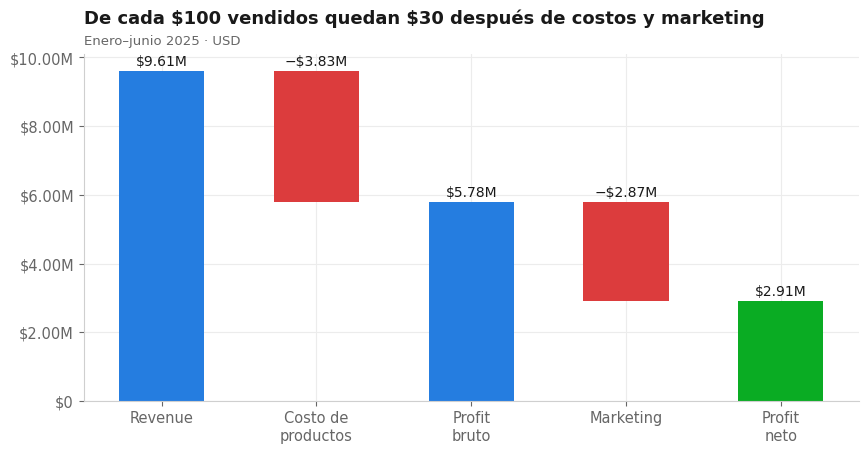

In [23]:
# cascada de rentabilidad (de revenue a profit neto)
pasos = ['Revenue', 'Costo de\nproductos', 'Profit\nbruto', 'Marketing', 'Profit\nneto']
valores = [revenue, -costo_total, profit_bruto, -gasto_marketing, profit_neto]
bases = [0, revenue - costo_total, 0, profit_neto, 0]
alturas = [revenue, costo_total, profit_bruto, gasto_marketing, profit_neto]
colores = [AZUL, ROJO, AZUL, ROJO, VERDE]

fig, ax = plt.subplots(figsize=(10, 4.5))
barras = ax.bar(pasos, alturas, bottom=bases, color=colores, width=0.55)
for b, v in zip(barras, valores):
    ax.annotate(dinero(v), (b.get_x() + b.get_width() / 2, b.get_y() + b.get_height()),
                xytext=(0, 4), textcoords='offset points', ha='center', fontsize=10, color=TEXTO)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(dinero))
titulo(ax, f'De cada $100 vendidos quedan ${profit_neto / revenue * 100:.0f} después de costos y marketing',
       'Enero–junio 2025 · USD')
plt.show()

In [24]:
# 📈 Parte 2: Comportamiento de ventas
print('¿Cada fila es un pedido distinto?', ventas['id_pedido'].is_unique)
ticket_promedio = ventas['monto_total'].mean()
productos_por_orden = ventas['cantidad'].mean()

unidades_producto = (ventas.groupby('nombre_producto')
                     .agg(unidades=('cantidad', 'sum'), pedidos=('id_pedido', 'count'), revenue=('monto_total', 'sum'))
                     .sort_values('unidades', ascending=False))
marketing_canal = marketing.groupby('canal')['gasto'].sum().sort_values(ascending=False)

print(f'Ticket promedio por orden            : ${ticket_promedio:,.2f}  (mediana ${ventas["monto_total"].median():,.2f})')
print(f'Cantidad promedio de productos/orden : {productos_por_orden:.2f}')
print(f'Producto más vendido (unidades)      : {unidades_producto.index[0]} ({unidades_producto["unidades"].iat[0]:,} unidades)')
print(f'Producto con más revenue             : {unidades_producto["revenue"].idxmax()}')
print()
display(unidades_producto)
display(marketing_canal.to_frame('gasto (USD)').assign(**{'% del total': lambda d: d['gasto (USD)'] / d['gasto (USD)'].sum() * 100}))

¿Cada fila es un pedido distinto? True
Ticket promedio por orden            : $385.85  (mediana $341.41)
Cantidad promedio de productos/orden : 1.50
Producto más vendido (unidades)      : Vacuum-Pro-Black (6,284 unidades)
Producto con más revenue             : Vacuum-Pro-Black



,unidades,pedidos,revenue
nombre_producto,,,
Vacuum-Pro-Black,6284,4170,"1,621,051.85"
Blender-XL-Red,6279,4176,"1,611,574.59"
Jacket-Winter-M,6256,4166,"1,606,586.17"
Sneakers-Urban-42,6172,4129,"1,566,075.93"
Laptop-Gaming-16GB,4198,2768,"1,084,672.98"
Tablet-Standard-64GB,4153,2764,"1,062,922.80"
Phone-Pro-128GB,4140,2733,"1,057,134.62"


,gasto (USD),% del total
canal,,
social,"976,818.37",34.01
organic,"972,650.96",33.87
paid_search,"922,374.20",32.12


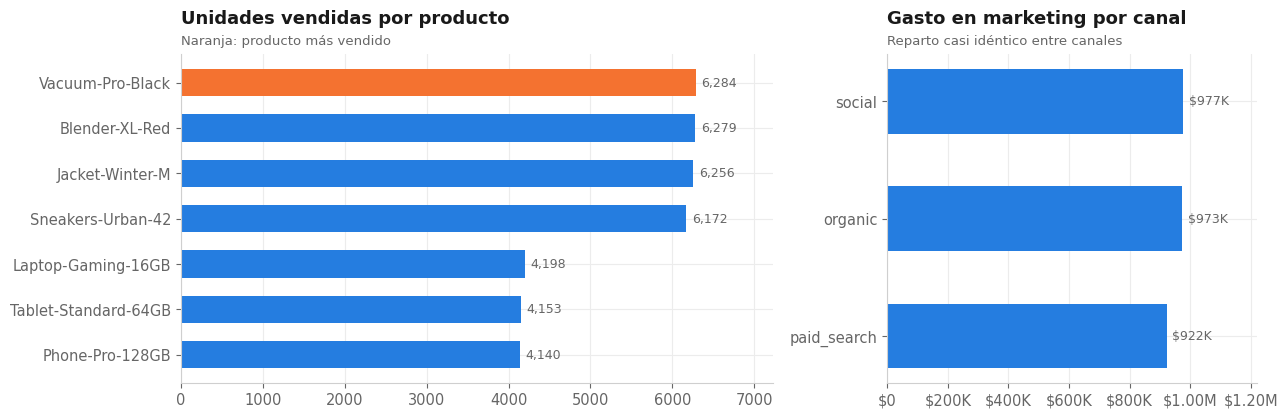

In [25]:
#  unidades vendidas por producto y gasto de marketing por canal
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={'width_ratios': [1.6, 1]})
up = unidades_producto['unidades'].sort_values()
b = axes[0].barh(up.index, up.values, color=[NARANJA if p == up.idxmax() else AZUL for p in up.index], height=0.6)
etiquetar_barras(axes[0], b, up.values, lambda v: f'{v:,.0f}', horizontal=True)
titulo(axes[0], 'Unidades vendidas por producto', 'Naranja: producto más vendido')
axes[0].set_xlim(0, up.max() * 1.15)

mc = marketing_canal.sort_values()
b = axes[1].barh(mc.index, mc.values, color=AZUL, height=0.55)
etiquetar_barras(axes[1], b, mc.values, dinero, horizontal=True)
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(dinero))
axes[1].set_xlim(0, mc.max() * 1.25)
titulo(axes[1], 'Gasto en marketing por canal', 'Reparto casi idéntico entre canales')
plt.tight_layout()
plt.show()

###  ¿qué productos generan (o destruyen) valor?

Los KPIs totales esconden diferencias enormes por producto. Aquí se calcula el profit, el margen y el porcentaje de pedidos que **se vendieron por debajo del costo**.

,categoria,pedidos,unidades,revenue,costo,profit,precio_promedio,costo_unitario,pct_pedidos_bajo_costo,margen %
nombre_producto,,,,,,,,,,
Vacuum-Pro-Black,Hogar,4170,6284,"1,621,051.85","104,314.40","1,516,737.45",261.02,16.60,0.24,93.57
Sneakers-Urban-42,Moda,4129,6172,"1,566,075.93","106,220.12","1,459,855.81",257.23,17.21,0.75,93.22
Phone-Pro-128GB,Electrónica,2733,4140,"1,057,134.62","41,896.80","1,015,237.82",259.53,10.12,0.07,96.04
Tablet-Standard-64GB,Electrónica,2764,4153,"1,062,922.80","104,697.13","958,225.67",257.53,25.21,1.74,90.15
Blender-XL-Red,Hogar,4176,6279,"1,611,574.59","1,109,122.56","502,452.03",259.16,176.64,33.86,31.18
Jacket-Winter-M,Moda,4166,6256,"1,606,586.17","1,184,323.36","422,262.81",259.82,189.31,36.61,26.28
Laptop-Gaming-16GB,Electrónica,2768,4198,"1,084,672.98","1,178,294.64","-93,621.66",261.27,280.68,54.12,-8.63


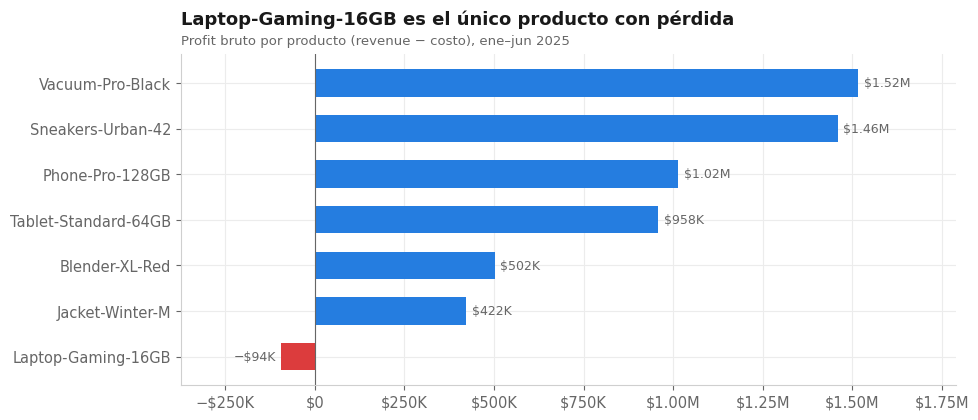

In [26]:
rent_producto = ventas.groupby('nombre_producto').agg(
    categoria=('categoria_producto', 'first'), pedidos=('id_pedido', 'count'), unidades=('cantidad', 'sum'),
    revenue=('monto_total', 'sum'), costo=('costo_total', 'sum'), profit=('profit', 'sum'),
    precio_promedio=('precio_unitario', 'mean'), costo_unitario=('costo_unitario', 'first'),
    pct_pedidos_bajo_costo=('profit', lambda s: (s < 0).mean() * 100))
rent_producto['margen %'] = rent_producto['profit'] / rent_producto['revenue'] * 100
rent_producto = rent_producto.sort_values('profit', ascending=False)
display(rent_producto)

fig, ax = plt.subplots(figsize=(10, 4.3))
rp = rent_producto['profit'].sort_values()
b = ax.barh(rp.index, rp.values, color=[ROJO if v < 0 else AZUL for v in rp.values], height=0.6)
etiquetar_barras(ax, b, rp.values, dinero, horizontal=True)
ax.axvline(0, color=TEXTO_2, linewidth=0.8)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(dinero))
ax.set_xlim(rp.min() * 4, rp.max() * 1.18)
titulo(ax, 'Laptop-Gaming-16GB es el único producto con pérdida',
       'Profit bruto por producto (revenue − costo), ene–jun 2025')
plt.show()

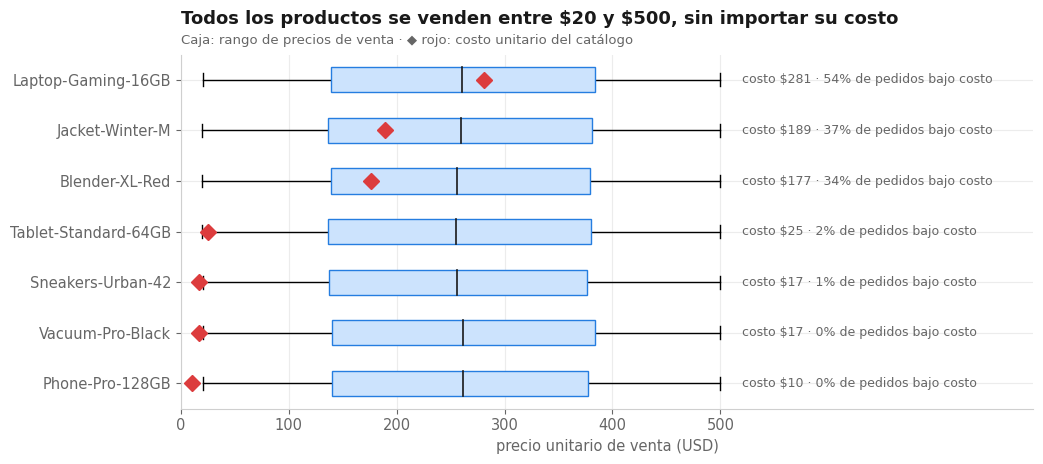

Pedidos vendidos por debajo del costo: 4,528 (18.2%)
Pérdida acumulada en esos pedidos    : $665,568
➡ Con un precio mínimo igual al costo (y la misma demanda), el profit bruto subiría de $5,781,150 a $6,446,718 (+11.5%).


In [27]:
# el precio de venta no está ligado al costo → muchos pedidos se venden con pérdida
orden = rent_producto.sort_values('costo_unitario').index.tolist()
fig, ax = plt.subplots(figsize=(11, 4.6))
datos = [ventas.loc[ventas['nombre_producto'] == p, 'precio_unitario'] for p in orden]
bp = ax.boxplot(datos, vert=False, patch_artist=True, widths=0.5, showfliers=False,
                medianprops=dict(color=TEXTO, linewidth=1.2))
ax.set_yticks(range(1, len(orden) + 1)); ax.set_yticklabels(orden)
for caja in bp['boxes']:
    caja.set(facecolor='#cce3fd', edgecolor=AZUL, linewidth=1)
for i, p in enumerate(orden, start=1):
    c = rent_producto.loc[p, 'costo_unitario']
    ax.plot(c, i, marker='D', color=ROJO, markersize=8, zorder=3)
    ax.annotate(f'costo ${c:,.0f} · {rent_producto.loc[p, "pct_pedidos_bajo_costo"]:.0f}% de pedidos bajo costo', (520, i),
                va='center', fontsize=9, color=TEXTO_2)
ax.set_xlim(0, 790)
ax.set_xticks(range(0, 600, 100))
ax.set_xlabel('precio unitario de venta (USD)')
titulo(ax, 'Todos los productos se venden entre $20 y $500, sin importar su costo',
       'Caja: rango de precios de venta · ◆ rojo: costo unitario del catálogo')
plt.show()

perdida_bajo_costo = ventas.loc[ventas['profit'] < 0, 'profit'].sum()
print(f'Pedidos vendidos por debajo del costo: {(ventas["profit"] < 0).sum():,} ({(ventas["profit"] < 0).mean():.1%})')
print(f'Pérdida acumulada en esos pedidos    : ${-perdida_bajo_costo:,.0f}')
print(f'➡ Con un precio mínimo igual al costo (y la misma demanda), el profit bruto subiría de ${profit_bruto:,.0f}'
      f' a ${profit_bruto - perdida_bajo_costo:,.0f} (+{-perdida_bajo_costo / profit_bruto:.1%}).')

### rentabilidad por segmento (país, dispositivo, canal y categoría)

In [28]:
segmentos = {}
for col, etiqueta in [('pais', 'País'), ('dispositivo', 'Dispositivo'), ('fuente_referencia', 'Canal de adquisición'),
                      ('categoria_producto', 'Categoría')]:
    t = ventas.groupby(col).agg(pedidos=('id_pedido', 'count'), revenue=('monto_total', 'sum'), profit=('profit', 'sum'),
                                ticket=('monto_total', 'mean'))
    t['margen %'] = t['profit'] / t['revenue'] * 100
    t['% del revenue'] = t['revenue'] / t['revenue'].sum() * 100
    segmentos[etiqueta] = t
    print(etiqueta)
    display(t.sort_values('revenue', ascending=False))

País


,pedidos,revenue,profit,ticket,margen %,% del revenue
pais,,,,,,
Mexico,8406,"3,245,422.63","1,952,292.24",386.08,60.16,33.77
Colombia,8359,"3,200,356.82","1,919,590.19",382.86,59.98,33.30
Argentina,8122,"3,157,426.04","1,905,306.70",388.75,60.34,32.86
Desconocido,19,"6,813.45","3,960.80",358.60,58.13,0.07


Dispositivo


,pedidos,revenue,profit,ticket,margen %,% del revenue
dispositivo,,,,,,
desktop,12671,"4,905,258.03","2,942,371.52",387.12,59.98,51.04
mobile,12233,"4,704,350.07","2,838,419.20",384.56,60.34,48.95
desconocido,2,410.84,359.21,205.42,87.43,0.00


Canal de adquisición


,pedidos,revenue,profit,ticket,margen %,% del revenue
fuente_referencia,,,,,,
social,8382,"3,222,510.32","1,909,774.53",384.46,59.26,33.53
paid_search,8257,"3,209,280.07","1,968,321.01",388.67,61.33,33.40
organic,8267,"3,178,228.55","1,903,054.39",384.45,59.88,33.07


Categoría


,pedidos,revenue,profit,ticket,margen %,% del revenue
categoria_producto,,,,,,
Hogar,8346,"3,232,626.44","2,019,189.48",387.33,62.46,33.64
Electrónica,8265,"3,204,730.40","1,879,841.83",387.75,58.66,33.35
Moda,8295,"3,172,662.10","1,882,118.62",382.48,59.32,33.01


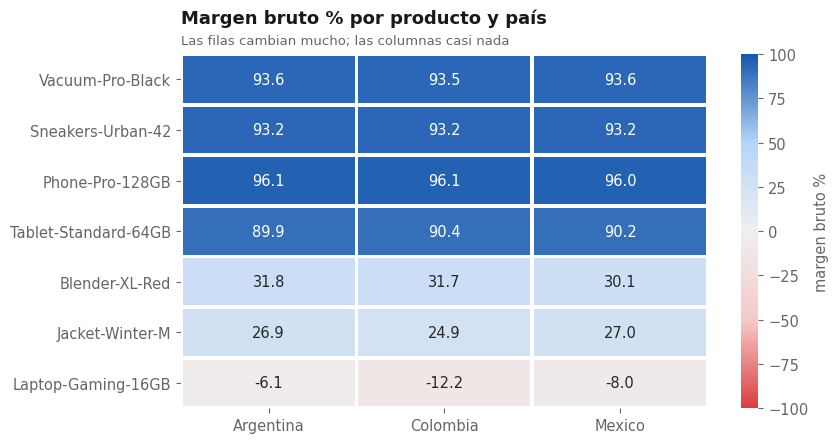

In [29]:
# margen por país y producto — el producto explica la rentabilidad, el país no
margen_pp = ventas.pivot_table(index='nombre_producto', columns='pais', values=['profit', 'monto_total'], aggfunc='sum')
margen_pp = (margen_pp['profit'] / margen_pp['monto_total'] * 100).drop(columns='Desconocido', errors='ignore')
margen_pp = margen_pp.loc[rent_producto.index]

fig, ax = plt.subplots(figsize=(8.5, 4.6))
sns.heatmap(margen_pp, annot=True, fmt='.1f', cmap=CMAP_DIV, center=0, vmin=-100, vmax=100, linewidths=2,
            linecolor='white', cbar_kws={'label': 'margen bruto %'}, ax=ax)
ax.set_xlabel(''); ax.set_ylabel('')
titulo(ax, 'Margen bruto % por producto y país', 'Las filas cambian mucho; las columnas casi nada')
plt.show()

### evolución mensual

,pedidos,clientes,revenue,profit_bruto,marketing,profit_neto,dias,revenue_diario,margen_neto %
mes,,,,,,,,,
2025-01,4312,3296,"1,654,676.90","993,266.47","500,186.60","493,079.87",31,"53,376.67",29.80
2025-02,3736,2946,"1,439,010.50","856,549.29","448,321.64","408,227.65",28,"51,393.23",28.37
2025-03,4255,3285,"1,657,796.32","999,727.40","516,014.46","483,712.94",31,"53,477.30",29.18
2025-04,4205,3258,"1,595,409.02","949,496.38","445,179.82","504,316.56",30,"53,180.30",31.61
2025-05,4236,3307,"1,648,037.26","1,007,792.61","499,181.34","508,611.27",31,"53,162.49",30.86
2025-06,4162,3218,"1,615,088.94","974,317.78","462,959.67","511,358.11",30,"53,836.30",31.66


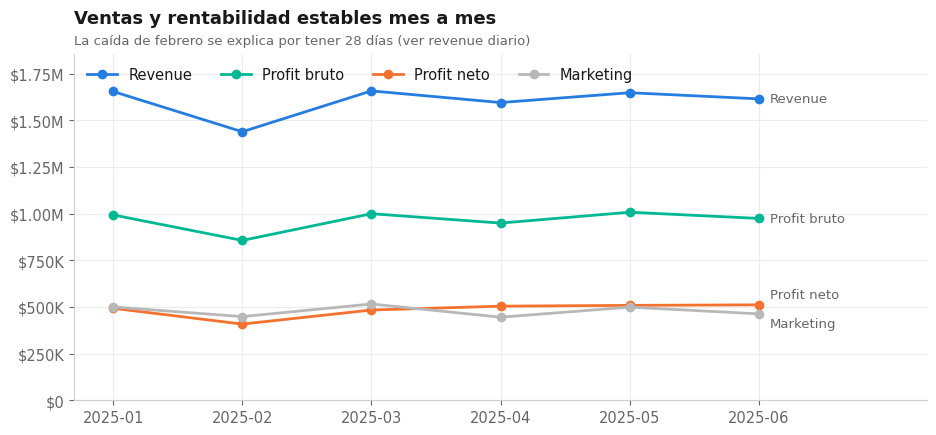

In [30]:
mensual = ventas.groupby('mes').agg(pedidos=('id_pedido', 'count'), clientes=('id_usuario', 'nunique'),
                                    revenue=('monto_total', 'sum'), profit_bruto=('profit', 'sum'))
mensual = mensual.join(marketing.assign(mes=marketing['fecha'].dt.to_period('M').astype(str)).groupby('mes')['gasto'].sum()
                       .rename('marketing'))
mensual['profit_neto'] = mensual['profit_bruto'] - mensual['marketing']
mensual['dias'] = ventas.groupby('mes')['fecha_hora_pedido'].apply(lambda s: s.dt.date.nunique())
mensual['revenue_diario'] = mensual['revenue'] / mensual['dias']
mensual['margen_neto %'] = mensual['profit_neto'] / mensual['revenue'] * 100
display(mensual)

fig, ax = plt.subplots(figsize=(11, 4.5))
x = range(len(mensual))
for col, color, nombre in [('revenue', AZUL, 'Revenue'), ('profit_bruto', AQUA, 'Profit bruto'),
                           ('profit_neto', NARANJA, 'Profit neto'), ('marketing', GRIS, 'Marketing')]:
    ax.plot(x, mensual[col], marker='o', color=color, linewidth=2, markersize=6, label=nombre)
    desplaz = {'profit_neto': 7, 'marketing': -7}.get(col, 0)
    ax.annotate(nombre, (len(mensual) - 1, mensual[col].iat[-1]), xytext=(8, desplaz), textcoords='offset points',
                va='center', color=TEXTO_2, fontsize=9.5)
ax.set_xticks(list(x)); ax.set_xticklabels(mensual.index)
ax.set_xlim(-0.3, len(mensual) + 0.3)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(dinero))
ax.set_ylim(0, mensual['revenue'].max() * 1.12)
ax.legend(loc='upper left', ncol=4)
titulo(ax, 'Ventas y rentabilidad estables mes a mes', 'La caída de febrero se explica por tener 28 días (ver revenue diario)')
plt.show()

###  eficiencia del marketing por país y canal

Los pedidos traen su `fuente_referencia` (organic, paid_search, social) y su país, igual que el gasto de marketing. Esto permite comparar **lo que cada canal costó** contra **lo que generó**:

- **ROAS** = revenue atribuido / gasto
- **ROI** = (profit bruto atribuido − gasto) / gasto

⚠️ Supuesto: se atribuye cada pedido al canal de su `fuente_referencia` (último toque). El canal *organic* también tiene gasto (SEO/contenido), por eso se incluye.

,pais,canal,gasto,pedidos,revenue,profit_bruto,ROAS,ROI,costo_por_pedido
1,Argentina,paid_search,"297,321.98",2689,"1,066,815.09","650,160.77",3.59,1.19,110.57
4,Colombia,paid_search,"298,901.96",2753,"1,052,016.24","648,822.43",3.52,1.17,108.57
5,Colombia,social,"313,528.95",2846,"1,092,229.47","654,923.98",3.48,1.09,110.16
7,Mexico,paid_search,"326,150.26",2805,"1,086,743.40","666,864.83",3.33,1.04,116.27
0,Argentina,organic,"319,196.99",2737,"1,059,626.42","649,288.62",3.32,1.03,116.62
8,Mexico,social,"332,113.79",2834,"1,097,079.88","647,923.17",3.30,0.95,117.19
6,Mexico,organic,"330,231.46",2767,"1,061,599.35","637,504.24",3.21,0.93,119.35
3,Colombia,organic,"323,222.51",2760,"1,056,111.11","615,843.78",3.27,0.91,117.11
2,Argentina,social,"331,175.63",2696,"1,030,984.53","605,857.31",3.11,0.83,122.84


,gasto,revenue,profit_bruto,pedidos,ROAS,ROI
canal,,,,,,
paid_search,"922,374.20","3,205,574.73","1,965,848.03",8247,3.48,1.13
organic,"972,650.96","3,177,336.88","1,902,636.64",8264,3.27,0.96
social,"976,818.37","3,220,293.88","1,908,704.46",8376,3.30,0.95


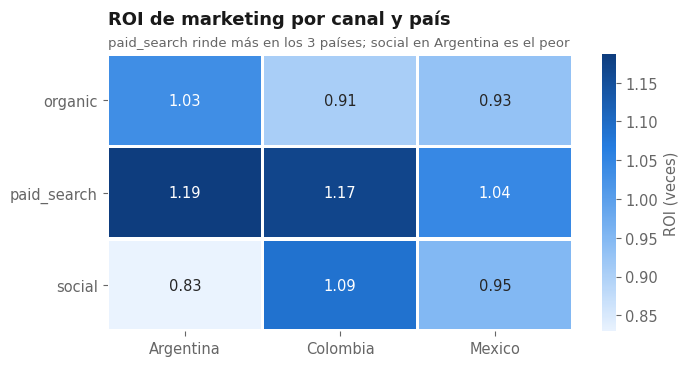

In [31]:
atribucion = (ventas.groupby(['pais', 'fuente_referencia'])
              .agg(pedidos=('id_pedido', 'count'), revenue=('monto_total', 'sum'), profit_bruto=('profit', 'sum'))
              .reset_index().rename(columns={'fuente_referencia': 'canal'}))
eficiencia = (marketing.groupby(['pais', 'canal'])['gasto'].sum().reset_index()
              .merge(atribucion, on=['pais', 'canal'], how='left'))
eficiencia['ROAS'] = eficiencia['revenue'] / eficiencia['gasto']
eficiencia['ROI'] = (eficiencia['profit_bruto'] - eficiencia['gasto']) / eficiencia['gasto']
eficiencia['costo_por_pedido'] = eficiencia['gasto'] / eficiencia['pedidos']
display(eficiencia.sort_values('ROI', ascending=False))

por_canal = eficiencia.groupby('canal')[['gasto', 'revenue', 'profit_bruto', 'pedidos']].sum()
por_canal['ROAS'] = por_canal['revenue'] / por_canal['gasto']
por_canal['ROI'] = (por_canal['profit_bruto'] - por_canal['gasto']) / por_canal['gasto']
display(por_canal.sort_values('ROI', ascending=False))

fig, ax = plt.subplots(figsize=(7.5, 3.6))
sns.heatmap(eficiencia.pivot(index='canal', columns='pais', values='ROI'), annot=True, fmt='.2f', cmap=CMAP_AZUL,
            linewidths=2, linecolor='white', cbar_kws={'label': 'ROI (veces)'}, ax=ax)
ax.set_xlabel(''); ax.set_ylabel('')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
titulo(ax, 'ROI de marketing por canal y país', 'paid_search rinde más en los 3 países; social en Argentina es el peor')
plt.show()

###  clientes y economía unitaria

Clientes únicos                       : 7,640
Pedidos por cliente (6 meses)         : 3.26
Tasa de recompra (2+ pedidos)         : 85.4%
Revenue por cliente                   : $1,258
Profit bruto por cliente              : $757
Costo de marketing por cliente (CAC*) : $376
Profit bruto por cliente / CAC        : 2.01x
Share de revenue del top 20% clientes : 39.8%
Descuentos otorgados                  : $112,195 (1.2% de la venta bruta); 50% de los pedidos tuvo descuento


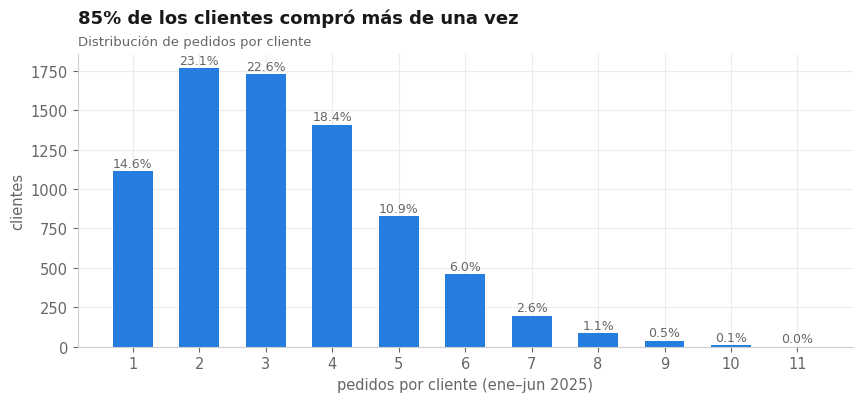

In [32]:
clientes = ventas.groupby('id_usuario').agg(pedidos=('id_pedido', 'count'), revenue=('monto_total', 'sum'),
                                             profit=('profit', 'sum'))
n_clientes = len(clientes)
recompra = (clientes['pedidos'] > 1).mean()
top20 = clientes['revenue'].sort_values(ascending=False).head(int(n_clientes * 0.2)).sum() / clientes['revenue'].sum()
cac = gasto_marketing / n_clientes   # todos los clientes del periodo se consideran adquiridos en él (supuesto)

print(f'Clientes únicos                       : {n_clientes:,}')
print(f'Pedidos por cliente (6 meses)         : {clientes["pedidos"].mean():.2f}')
print(f'Tasa de recompra (2+ pedidos)         : {recompra:.1%}')
print(f'Revenue por cliente                   : ${clientes["revenue"].mean():,.0f}')
print(f'Profit bruto por cliente              : ${clientes["profit"].mean():,.0f}')
print(f'Costo de marketing por cliente (CAC*) : ${cac:,.0f}')
print(f'Profit bruto por cliente / CAC        : {clientes["profit"].mean() / cac:.2f}x')
print(f'Share de revenue del top 20% clientes : {top20:.1%}')
print(f'Descuentos otorgados                  : ${ventas["monto_descuento"].sum():,.0f} '
      f'({ventas["monto_descuento"].sum() / (revenue + ventas["monto_descuento"].sum()):.1%} de la venta bruta); '
      f'{(ventas["monto_descuento"] > 0).mean():.0%} de los pedidos tuvo descuento')

fig, ax = plt.subplots(figsize=(10, 3.8))
dist = clientes['pedidos'].value_counts().sort_index()
b = ax.bar(dist.index.astype(str), dist.values, color=AZUL, width=0.6)
etiquetar_barras(ax, b, dist.values / n_clientes * 100, lambda v: f'{v:.1f}%')
ax.set_xlabel('pedidos por cliente (ene–jun 2025)'); ax.set_ylabel('clientes')
titulo(ax, f'{recompra:.0%} de los clientes compró más de una vez', 'Distribución de pedidos por cliente')
plt.show()

In [33]:
#  tabla resumen de KPIs (se reutiliza en las conclusiones y en el dashboard)
kpis = pd.Series({
    'Revenue total (USD)': revenue,
    'Costo total (USD)': costo_total,
    'Profit bruto (USD)': profit_bruto,
    'Margen bruto %': profit_bruto / revenue * 100,
    'Inversión en marketing (USD)': gasto_marketing,
    'Profit neto después de marketing (USD)': profit_neto,
    'Margen neto %': profit_neto / revenue * 100,
    'Pedidos': len(ventas),
    'Clientes': n_clientes,
    'Ticket promedio (USD)': ticket_promedio,
    'Productos promedio por orden': productos_por_orden,
}).to_frame('valor')
display(kpis)

,valor
Revenue total (USD),"9,610,018.94"
Costo total (USD),"3,828,869.01"
Profit bruto (USD),"5,781,149.93"
Margen bruto %,60.16
Inversión en marketing (USD),"2,871,843.53"
Profit neto después de marketing (USD),"2,909,306.40"
Margen neto %,30.27
Pedidos,"24,906.00"
Clientes,"7,640.00"
Ticket promedio (USD),385.85


💡 **Insight Paso 2 — ¿Estamos ganando dinero?** **Sí.** En el semestre RappiPlus vendió **$9.61M**, con un margen bruto de **60.2 %** y, después de invertir **$2.87M** en marketing, deja **$2.91M de profit neto (30.3 %)**. Pero hay tres alertas:

1. **Precios desconectados del costo.** Cada producto se vende entre $20 y $500 sin relación con su costo. Por eso **Laptop-Gaming-16GB pierde dinero** (−$94K, 54 % de sus pedidos bajo costo) y Jacket y Blender venden más de un tercio de sus pedidos con pérdida. En total, **18 % de los pedidos se vendió por debajo del costo, con una pérdida acumulada de $666K**: un **precio mínimo igual al costo** habría elevado el profit bruto un 11.5 % (asumiendo la misma demanda).
2. **Marketing repartido "en partes iguales".** El gasto es casi idéntico entre canales, pero **paid_search tiene el mejor ROI en los tres países**, mientras que social en Argentina es el canal menos eficiente. Hay espacio para reasignar presupuesto.
3. **La rentabilidad depende del producto, no del segmento.** País, dispositivo y canal tienen márgenes casi iguales (~60 %); la palanca está en precios y mezcla de productos.

Los clientes recompran mucho (85 % hizo 2+ pedidos) y cada cliente deja ~2× su costo de marketing en profit bruto.

---

## 🔹 Paso 3: Entender dónde se pierden los usuarios (funnel de conversión)

**🎯 Objetivo:** Analizar el comportamiento de los usuarios para identificar en qué etapa del proceso se pierden.


⚙️**Conexión a la base de datos**:  
Se ejecuta la línea de configuración para conectar con la base de datos y aplicar consultas SQL en la tabla **events**.

---

**📊 Parte 1: Construcción del funnel**
- ¿Cuántos usuarios llegan a cada etapa del funnel?  
- Se calcula el número de usuarios únicos por `nombre_evento`  
- Se ordenan los eventos según el flujo del usuario  

---

**📉 Parte 2: Análisis de conversión**
- Se calcula la tasa de conversión entre cada paso del funnel  
- Se identifica en qué etapa se pierde la mayor cantidad de usuarios  
- ¿Cuál es la tasa de conversión final?
---

In [34]:
import pandas as pd
from sqlalchemy import create_engine

# ======================
# Conexión (NO modificar)
# ======================
db_config = {
    'user': 'practicum_student',
    'pwd': 'QnmDH8Sc2TQLvy2G3Vvh7',
    'host': 'yp-trainers-practicum.cluster-czs0gxyx2d8w.us-east-1.rds.amazonaws.com',
    'port': 5432,
    'db': 'data-analyst-production-db-en'
}

connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db']
)

engine = create_engine(connection_string, connect_args={'sslmode':'require'})

In [35]:
# Explorar tabla events
# =========================
query_events = '''
SELECT *
FROM events;
'''
events = pd.read_sql(query_events, con=engine)
events.head()

,id_usuario,id_sesion,nombre_evento,timestamp_evento,pais,dispositivo,fuente_referencia,categoria_producto
0,user_6772,6a97f2af-32ae-4186-8c92-04025be1a27b,first_visit,2025-05-17,Colombia,desktop,organic,Moda
1,user_5883,369b767c-1c33-4b2f-a652-c7c0ef92cfc9,add_to_cart,2025-02-23,Mexico,mobile,social,Hogar
2,user_5946,60039041-e78b-474c-87b3-c0b7e9c30708,add_payment_info,2025-05-15,Colombia,desktop,social,Electronica
3,user_827,18252a64-f389-4ef7-9e58-dadad4a3491e,purchase,2025-03-31,Mexico,mobile,social,Moda
4,user_2361,221b364e-cdc5-4668-b698-18d5ba849a67,first_visit,2025-01-22,Argentina,desktop,paid_search,Electronica


In [36]:
#  calidad de la tabla events directamente en SQL
query_calidad_events = '''
SELECT COUNT(*)                                                  AS filas,
       COUNT(DISTINCT id_usuario)                                AS usuarios,
       COUNT(DISTINCT id_sesion)                                 AS sesiones,
       COUNT(*) - COUNT(DISTINCT (id_usuario, id_sesion, nombre_evento, timestamp_evento)) AS duplicados,
       SUM(CASE WHEN id_usuario IS NULL OR nombre_evento IS NULL
                  OR timestamp_evento IS NULL THEN 1 ELSE 0 END)  AS filas_con_nulos,
       MIN(CAST(timestamp_evento AS DATE))                       AS primera_fecha,
       MAX(CAST(timestamp_evento AS DATE))                       AS ultima_fecha
FROM events;
'''
display(pd.read_sql(query_calidad_events, con=engine))
events.info()
print()
print('Eventos registrados:', events['nombre_evento'].value_counts().to_dict())

,filas,usuarios,sesiones,duplicados,filas_con_nulos,primera_fecha,ultima_fecha
0,120000,8000,120000,0,0,2025-01-01,2025-06-30


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 8 columns):
 #   Column              Non-Null Count   Dtype 
---  ------              --------------   ----- 
 0   id_usuario          120000 non-null  object
 1   id_sesion           120000 non-null  object
 2   nombre_evento       120000 non-null  object
 3   timestamp_evento    120000 non-null  object
 4   pais                120000 non-null  object
 5   dispositivo         120000 non-null  object
 6   fuente_referencia   120000 non-null  object
 7   categoria_producto  120000 non-null  object
dtypes: object(8)
memory usage: 7.3+ MB

Eventos registrados: {'first_visit': 29957, 'add_to_cart': 24157, 'select_item': 23887, 'begin_checkout': 17971, 'add_payment_info': 12018, 'purchase': 12010}


📝 **Cómo se construye el funnel.** Hay 120,000 filas y 120,000 sesiones distintas: **cada sesión contiene un solo evento** y las fechas no tienen hora. Por eso no se puede seguir el recorrido *dentro* de una sesión, y el funnel se mide **a nivel usuario**: cuántos usuarios únicos alcanzaron cada etapa en el periodo. El orden sigue el flujo estándar de e-commerce (GA4):

`first_visit → select_item → add_to_cart → begin_checkout → add_payment_info → purchase`

In [37]:
# PARTE 1: Totales del funnel
# ======================

query_totals = '''
SELECT nombre_evento,
       COUNT(DISTINCT id_usuario) AS usuarios_unicos,
       COUNT(*)                   AS total_eventos
FROM events
GROUP BY nombre_evento
ORDER BY CASE nombre_evento
             WHEN 'first_visit'      THEN 1
             WHEN 'select_item'      THEN 2
             WHEN 'add_to_cart'      THEN 3
             WHEN 'begin_checkout'   THEN 4
             WHEN 'add_payment_info' THEN 5
             WHEN 'purchase'         THEN 6
         END;
'''

totals = pd.read_sql(query_totals, con=engine)
totals

,nombre_evento,usuarios_unicos,total_eventos
0,first_visit,7796,29957
1,select_item,7582,23887
2,add_to_cart,7634,24157
3,begin_checkout,7208,17971
4,add_payment_info,6250,12018
5,purchase,6240,12010


In [38]:
# PARTE 2: Conversiones
# ======================

query_conversion = '''
WITH funnel AS (
    SELECT nombre_evento,
           CASE nombre_evento
               WHEN 'first_visit'      THEN 1
               WHEN 'select_item'      THEN 2
               WHEN 'add_to_cart'      THEN 3
               WHEN 'begin_checkout'   THEN 4
               WHEN 'add_payment_info' THEN 5
               WHEN 'purchase'         THEN 6
           END                        AS paso,
           COUNT(DISTINCT id_usuario) AS usuarios
    FROM events
    GROUP BY nombre_evento
)
SELECT paso,
       nombre_evento,
       usuarios,
       LAG(usuarios) OVER (ORDER BY paso)                                    AS usuarios_paso_anterior,
       LAG(usuarios) OVER (ORDER BY paso) - usuarios                         AS usuarios_perdidos,
       ROUND(100.0 * usuarios / LAG(usuarios) OVER (ORDER BY paso), 2)       AS conversion_paso_pct,
       ROUND(100.0 * usuarios / FIRST_VALUE(usuarios) OVER (ORDER BY paso), 2) AS conversion_acumulada_pct
FROM funnel
ORDER BY paso;
'''

conversion = pd.read_sql(query_conversion, con=engine)
conversion

,paso,nombre_evento,usuarios,usuarios_paso_anterior,usuarios_perdidos,conversion_paso_pct,conversion_acumulada_pct
0,1,first_visit,7796,NaN,NaN,NaN,100.00
1,2,select_item,7582,"7,796.00",214.00,97.26,97.26
2,3,add_to_cart,7634,"7,582.00",-52.00,100.69,97.92
3,4,begin_checkout,7208,"7,634.00",426.00,94.42,92.46
4,5,add_payment_info,6250,"7,208.00",958.00,86.71,80.17
5,6,purchase,6240,"6,250.00",10.00,99.84,80.04


In [39]:
# ¿Dónde se pierde la mayor cantidad de usuarios? ¿Cuál es la conversión final?
mayor = conversion.loc[conversion['usuarios_perdidos'].idxmax()]
anterior = conversion.loc[conversion['paso'] == mayor['paso'] - 1, 'nombre_evento'].iat[0]
conversion_final = conversion['conversion_acumulada_pct'].iat[-1]

print(f"🔻 Mayor abandono: {anterior} → {mayor['nombre_evento']}: se pierden {mayor['usuarios_perdidos']:,.0f} usuarios "
      f"({100 - mayor['conversion_paso_pct']:.1f} % de los que iniciaron ese paso)")
print(f"✅ Conversión final (first_visit → purchase): {conversion_final:.2f} %"
      f" → {conversion['usuarios'].iat[-1]:,} de {conversion['usuarios'].iat[0]:,} usuarios compraron")

# ➕ la misma lectura con eventos (volumen de interacciones) en lugar de usuarios
totals['conversion_eventos_pct'] = (totals['total_eventos'] / totals['total_eventos'].shift() * 100).round(2)
display(totals)

🔻 Mayor abandono: begin_checkout → add_payment_info: se pierden 958 usuarios (13.3 % de los que iniciaron ese paso)
✅ Conversión final (first_visit → purchase): 80.04 % → 6,240 de 7,796 usuarios compraron


,nombre_evento,usuarios_unicos,total_eventos,conversion_eventos_pct
0,first_visit,7796,29957,NaN
1,select_item,7582,23887,79.74
2,add_to_cart,7634,24157,101.13
3,begin_checkout,7208,17971,74.39
4,add_payment_info,6250,12018,66.87
5,purchase,6240,12010,99.93


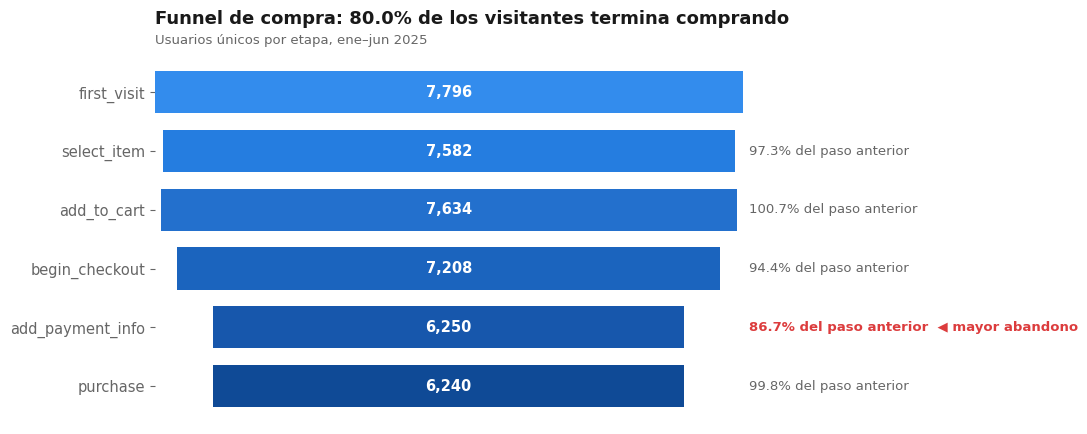

In [40]:
#  visualización del funnel
fig, ax = plt.subplots(figsize=(11, 4.8))
etapas = conversion['nombre_evento'].tolist()[::-1]
usuarios = conversion['usuarios'].tolist()[::-1]
tonos = ['#0f4a96', '#1757ac', '#1b64be', '#2370cd', '#257de0', '#338ced']  # rampa ordinal: más oscuro = etapa más profunda
maximo = max(usuarios)
for i, (e, u) in enumerate(zip(etapas, usuarios)):
    ax.barh(i, u, left=(maximo - u) / 2, color=tonos[i], height=0.72)
    ax.text(maximo / 2, i, f'{u:,}', ha='center', va='center', color='white', fontsize=10.5, fontweight='bold')
for _, fila in conversion.iloc[1:].iterrows():
    y = len(conversion) - fila['paso']
    es_mayor = fila['paso'] == mayor['paso']
    ax.annotate(f"{fila['conversion_paso_pct']:.1f}% del paso anterior" + ('  ◀ mayor abandono' if es_mayor else ''),
                (maximo * 1.01, y), va='center', fontsize=9.5, color=ROJO if es_mayor else TEXTO_2,
                fontweight='bold' if es_mayor else 'normal')
ax.set_yticks(range(len(etapas))); ax.set_yticklabels(etapas)
ax.set_xlim(0, maximo * 1.45); ax.set_xticks([]); ax.grid(False)
ax.spines['bottom'].set_visible(False); ax.spines['left'].set_visible(False)
titulo(ax, f'Funnel de compra: {conversion_final:.1f}% de los visitantes termina comprando',
       'Usuarios únicos por etapa, ene–jun 2025')
plt.show()

📝 `add_to_cart` tiene **más** usuarios que `select_item` (conversión > 100 %): hay usuarios que agregan al carrito sin un `select_item` registrado (por ejemplo, desde recomendaciones o el home). Es una señal de que el tracking no obliga a pasar por todas las etapas. El siguiente análisis lo cuantifica.

In [41]:
#  funnel "estricto" — usuarios que completaron cada etapa Y todas las anteriores
query_funnel_estricto = '''
WITH pasos AS (
    SELECT id_usuario,
           MAX(CASE WHEN nombre_evento = 'first_visit'      THEN 1 ELSE 0 END) AS p1,
           MAX(CASE WHEN nombre_evento = 'select_item'      THEN 1 ELSE 0 END) AS p2,
           MAX(CASE WHEN nombre_evento = 'add_to_cart'      THEN 1 ELSE 0 END) AS p3,
           MAX(CASE WHEN nombre_evento = 'begin_checkout'   THEN 1 ELSE 0 END) AS p4,
           MAX(CASE WHEN nombre_evento = 'add_payment_info' THEN 1 ELSE 0 END) AS p5,
           MAX(CASE WHEN nombre_evento = 'purchase'         THEN 1 ELSE 0 END) AS p6
    FROM events
    GROUP BY id_usuario
)
SELECT SUM(p1)                         AS first_visit,
       SUM(p1 * p2)                    AS select_item,
       SUM(p1 * p2 * p3)               AS add_to_cart,
       SUM(p1 * p2 * p3 * p4)          AS begin_checkout,
       SUM(p1 * p2 * p3 * p4 * p5)     AS add_payment_info,
       SUM(p1 * p2 * p3 * p4 * p5 * p6) AS purchase,
       SUM(CASE WHEN p6 = 1 AND p4 = 0 THEN 1 ELSE 0 END) AS compran_sin_begin_checkout,
       SUM(CASE WHEN p6 = 1 AND p5 = 0 THEN 1 ELSE 0 END) AS compran_sin_add_payment_info
FROM pasos;
'''
estricto = pd.read_sql(query_funnel_estricto, con=engine)
comparacion = conversion[['nombre_evento', 'usuarios']].rename(columns={'usuarios': 'funnel_abierto'})
comparacion['funnel_estricto'] = comparacion['nombre_evento'].map(estricto.iloc[0])
comparacion['conv_paso_estricto_pct'] = (comparacion['funnel_estricto'] / comparacion['funnel_estricto'].shift() * 100).round(2)
comparacion['conv_acum_estricto_pct'] = (comparacion['funnel_estricto'] / comparacion['funnel_estricto'].iat[0] * 100).round(2)
display(comparacion)
print('Compradores sin begin_checkout registrado :', int(estricto['compran_sin_begin_checkout'].iat[0]))
print('Compradores sin add_payment_info registrado:', int(estricto['compran_sin_add_payment_info'].iat[0]))

,nombre_evento,funnel_abierto,funnel_estricto,conv_paso_estricto_pct,conv_acum_estricto_pct
0,first_visit,7796,7796,NaN,100.00
1,select_item,7582,7393,94.83,94.83
2,add_to_cart,7634,7052,95.39,90.46
3,begin_checkout,7208,6364,90.24,81.63
4,add_payment_info,6250,4967,78.05,63.71
5,purchase,6240,3857,77.65,49.47


Compradores sin begin_checkout registrado : 624
Compradores sin add_payment_info registrado: 1382


nombre_evento            first_visit  select_item  add_to_cart  begin_checkout  add_payment_info  purchase  checkout → pago %  carrito → checkout %  visita → compra %
dimension   segmento                                                                                                                                                  
Canal       organic             5652         4992         5081            4228              3181      3158              75.24                 83.21              55.87
            paid_search         5700         5003         5062            4246              3153      3202              74.26                 83.88              56.18
            social              5693         5020         5063            4179              3136      3111              75.04                 82.54              54.65
Categoría   Electronica         5680         5007         5126            4227              3178      3177              75.18                 82.46              55.93
            Hogar               5695         5073         5014            4234              3139      3203              74.14                 84.44              56.24
            Moda                5694         4999         5094            4151              3117      3127              75.09                 81.49              54.92
Dispositivo desktop             3954         3846         3890            3646              3173      3173              87.03                 93.73              80.25
            mobile              3842         3736         3744            3562              3077      3067              86.38                 95.14              79.83
País        Argentina           2543         2483         2505            2353              2027      2070              86.15                 93.93              81.40
            Colombia            2635         2538         2561            2438              2105      2099              86.34                 95.20              79.66
            Mexico              2618         2561         2568            2417              2118      2071              87.63                 94.12              79.11

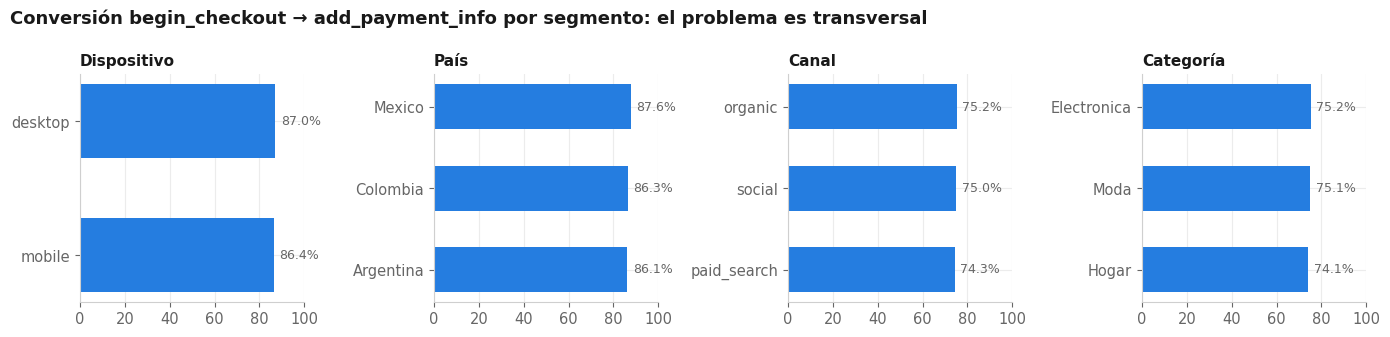

In [42]:
#  ¿el abandono cambia según dispositivo, país, canal o categoría?
query_funnel_segmentos = '''
SELECT 'Dispositivo' AS dimension, dispositivo AS segmento, nombre_evento, COUNT(DISTINCT id_usuario) AS usuarios
FROM events GROUP BY 1, 2, 3
UNION ALL
SELECT 'País', pais, nombre_evento, COUNT(DISTINCT id_usuario) FROM events GROUP BY 1, 2, 3
UNION ALL
SELECT 'Canal', fuente_referencia, nombre_evento, COUNT(DISTINCT id_usuario) FROM events GROUP BY 1, 2, 3
UNION ALL
SELECT 'Categoría', categoria_producto, nombre_evento, COUNT(DISTINCT id_usuario) FROM events GROUP BY 1, 2, 3;
'''
seg = pd.read_sql(query_funnel_segmentos, con=engine)
orden_etapas = conversion['nombre_evento'].tolist()
seg = seg.pivot_table(index=['dimension', 'segmento'], columns='nombre_evento', values='usuarios')[orden_etapas]
seg['checkout → pago %'] = seg['add_payment_info'] / seg['begin_checkout'] * 100
seg['carrito → checkout %'] = seg['begin_checkout'] / seg['add_to_cart'] * 100
seg['visita → compra %'] = seg['purchase'] / seg['first_visit'] * 100
display(seg.round(2))

fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharex=True)
for ax, dim in zip(axes, ['Dispositivo', 'País', 'Canal', 'Categoría']):
    d = seg.loc[dim, 'checkout → pago %'].sort_values()
    b = ax.barh(d.index, d.values, color=AZUL, height=0.55)
    etiquetar_barras(ax, b, d.values, lambda v: f'{v:.1f}%', horizontal=True)
    ax.set_title(dim, loc='left', fontsize=11)
    ax.set_xlim(0, 100)
fig.suptitle('Conversión begin_checkout → add_payment_info por segmento: el problema es transversal',
             x=0.01, ha='left', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

nombre_evento,first_visit,select_item,add_to_cart,begin_checkout,add_payment_info,purchase,checkout → pago %,visita → compra %
mes,,,,,,,,
2025-01,3789,3186,3252,2504,1815,1811,72.48,47.80
2025-02,3530,2909,3035,2383,1665,1721,69.87,48.75
2025-03,3734,3193,3135,2564,1835,1795,71.57,48.07
2025-04,3658,3080,3109,2544,1773,1696,69.69,46.36
2025-05,3763,3233,3252,2618,1842,1882,70.36,50.01
2025-06,3672,3121,3243,2474,1751,1712,70.78,46.62


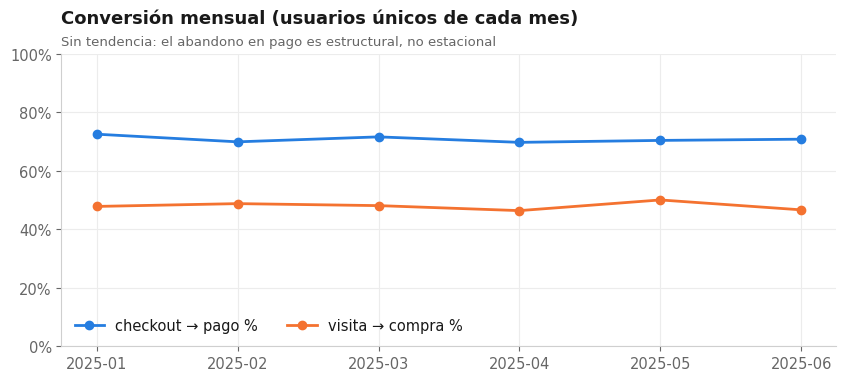

In [43]:
#  ¿el funnel mejora o empeora con el tiempo?
query_funnel_mensual = '''
SELECT CAST(DATE_TRUNC('month', CAST(timestamp_evento AS DATE)) AS DATE) AS mes,
       nombre_evento,
       COUNT(DISTINCT id_usuario) AS usuarios
FROM events
GROUP BY 1, 2
ORDER BY 1;
'''
fm = pd.read_sql(query_funnel_mensual, con=engine)
fm = fm.pivot(index='mes', columns='nombre_evento', values='usuarios')[orden_etapas]
fm.index = pd.to_datetime(fm.index).strftime('%Y-%m')
fm['checkout → pago %'] = fm['add_payment_info'] / fm['begin_checkout'] * 100
fm['visita → compra %'] = fm['purchase'] / fm['first_visit'] * 100
display(fm.round(2))

fig, ax = plt.subplots(figsize=(10, 3.8))
for col, color in [('checkout → pago %', AZUL), ('visita → compra %', NARANJA)]:
    ax.plot(fm.index, fm[col], marker='o', color=color, linewidth=2, label=col)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_ylim(0, 100)
ax.legend(loc='lower left', ncol=2)
titulo(ax, 'Conversión mensual (usuarios únicos de cada mes)', 'Sin tendencia: el abandono en pago es estructural, no estacional')
plt.show()

💡 **Insight Paso 3 — ¿Dónde se pierden los usuarios?** De 7,796 visitantes únicos, **6,240 compraron (80.0 %)**. La fuga más grande está en **`begin_checkout → add_payment_info`: 958 usuarios (13.3 %) inician el checkout y nunca registran un método de pago**, más del doble que la siguiente fuga (carrito → checkout, 5.6 %). En volumen de eventos la señal es aún más clara: solo 67 % de los checkouts llega a pago. Una vez ingresado el pago, prácticamente todos compran (99.8 %).

➕ Con el funnel **estricto** (exigir todas las etapas previas) solo el 49.5 % completa el recorrido completo, y la mayor caída **sigue siendo checkout → pago (−1,397 usuarios)**. El patrón se repite en todos los dispositivos, países, canales y categorías y en todos los meses (en canal y categoría el porcentaje es menor porque esos atributos cambian entre eventos del mismo usuario), así que **no es un problema de un segmento sino del paso de pago en sí**: es el lugar correcto para experimentar, justo lo que evalúa el test A/B del Paso 5. Además, 624 compradores no tienen `begin_checkout` y 1,382 no tienen `add_payment_info` registrado: hay huecos de tracking que conviene revisar con el equipo de producto.

---

## 🔹 Paso 4: Evaluar si los usuarios regresan (retención por cohortes)

**🎯 Objetivo:** Analizar la retención de usuarios para entender si regresan después de registrarse.

**Tablas**

- `users` 
- `user_activity` 

---
1. Se identifica la cohorte de cada usuario según el **mes de registro**.


2. Se calcula la retención semanal: cuántos usuarios **se mantienen activos** en cada semana desde su registro.
   - `retenido_w1`: usuarios activos en la semana 1  
   - `retenido_w2`: usuarios activos en la semana 2  
   - `retenido_w3`: usuarios activos en la semana 3  


3. Se calcula el porcentaje de retención para cada semana, dividiendo los usuarios retenidos entre los clientes iniciales de la cohorte:  
   - `semana_1`: porcentaje de usuarios retenidos en la semana 1  
   - `semana_2`: porcentaje de usuarios retenidos en la semana 2  
   - `semana_3`: porcentaje de usuarios retenidos en la semana 3  

Se revisa que la columna de fecha esté en formato correcto (`DATE`).  
Se realiza la conversión usando: `CAST(fecha_registro AS DATE)`

In [44]:
# Explorar tabla users
# =========================
query_users = '''
SELECT *
FROM users;
'''
users = pd.read_sql(query_users, con=engine)
users.head(3)

,id_usuario,fecha_registro,país,dispositivo,tipo_plan
0,user_0,2025-01-29,Mexico,mobile,free
1,user_1,2025-01-07,Mexico,mobile,free
2,user_2,2025-03-12,Argentina,mobile,free


In [45]:
# Explorar tabla user_activity
# =========================
query_user_activity = '''
SELECT *
FROM user_activity;
'''
user_activity = pd.read_sql(query_user_activity, con=engine)
user_activity.head(3)

,id_usuario,fecha_actividad,dias_despues_registro,activo
0,user_0,2025-02-05,7,0
1,user_0,2025-02-12,14,1
2,user_0,2025-02-19,21,1


In [46]:
#  calidad e integridad de users y user_activity
query_calidad_cohortes = '''
SELECT (SELECT COUNT(*) FROM users)                                   AS usuarios,
       (SELECT COUNT(DISTINCT id_usuario) FROM users)                 AS usuarios_unicos,
       (SELECT MIN(CAST(fecha_registro AS DATE)) FROM users)          AS primer_registro,
       (SELECT MAX(CAST(fecha_registro AS DATE)) FROM users)          AS ultimo_registro,
       (SELECT COUNT(*) FROM user_activity)                           AS filas_actividad,
       (SELECT COUNT(*) FROM user_activity a
          LEFT JOIN users u ON a.id_usuario = u.id_usuario
         WHERE u.id_usuario IS NULL)                                  AS actividad_sin_usuario,
       (SELECT COUNT(*) FROM user_activity a
          JOIN users u ON a.id_usuario = u.id_usuario
         WHERE CAST(a.fecha_actividad AS DATE) - CAST(u.fecha_registro AS DATE)
               <> a.dias_despues_registro)                            AS dias_inconsistentes;
'''
display(pd.read_sql(query_calidad_cohortes, con=engine))

query_checkpoints = '''
SELECT dias_despues_registro,
       COUNT(*)                         AS registros,
       COUNT(DISTINCT id_usuario)       AS usuarios,
       CAST(SUM(activo) AS INT)         AS activos,
       ROUND(100.0 * AVG(activo), 2)    AS pct_activos
FROM user_activity
GROUP BY dias_despues_registro
ORDER BY dias_despues_registro;
'''
display(pd.read_sql(query_checkpoints, con=engine))
print('Tipos de dato en la BD → users.fecha_registro:', users['fecha_registro'].dtype,
      '| user_activity.fecha_actividad:', user_activity['fecha_actividad'].dtype, '(texto → se usa CAST(... AS DATE))')

,usuarios,usuarios_unicos,primer_registro,ultimo_registro,filas_actividad,actividad_sin_usuario,dias_inconsistentes
0,8000,8000,2025-01-01,2025-05-31,32000,0,0


,dias_despues_registro,registros,usuarios,activos,pct_activos
0,7,8000,8000,3360,42.00
1,14,8000,8000,3355,41.94
2,21,8000,8000,3350,41.88
3,28,8000,8000,3250,40.63


Tipos de dato en la BD → users.fecha_registro: object | user_activity.fecha_actividad: object (texto → se usa CAST(... AS DATE))


📝 Cada usuario tiene exactamente **4 mediciones**, a los días 7, 14, 21 y 28 después de registrarse. Por eso *semana 1* = día 7, *semana 2* = día 14 y *semana 3* = día 21 (se calcula como `CEIL(dias_despues_registro / 7)`, lo que también funcionaría si hubiera mediciones intermedias). Todas las fechas son consistentes con `dias_despues_registro`.

In [47]:
# Retención por cohortes
# ======================

query_cohort_retention_final = '''
WITH cohortes AS (
    SELECT id_usuario,
           CAST(DATE_TRUNC('month', CAST(fecha_registro AS DATE)) AS DATE) AS cohorte
    FROM users
),
actividad AS (
    SELECT c.cohorte,
           c.id_usuario,
           MAX(CASE WHEN CEIL(a.dias_despues_registro / 7.0) = 1 AND a.activo = 1 THEN 1 ELSE 0 END) AS activo_w1,
           MAX(CASE WHEN CEIL(a.dias_despues_registro / 7.0) = 2 AND a.activo = 1 THEN 1 ELSE 0 END) AS activo_w2,
           MAX(CASE WHEN CEIL(a.dias_despues_registro / 7.0) = 3 AND a.activo = 1 THEN 1 ELSE 0 END) AS activo_w3
    FROM cohortes c
    LEFT JOIN user_activity a ON a.id_usuario = c.id_usuario
    GROUP BY c.cohorte, c.id_usuario
)
SELECT cohorte,
       COUNT(*)                                     AS clientes_iniciales,
       SUM(activo_w1)                               AS retenido_w1,
       SUM(activo_w2)                               AS retenido_w2,
       SUM(activo_w3)                               AS retenido_w3,
       ROUND(100.0 * SUM(activo_w1) / COUNT(*), 2)  AS semana_1,
       ROUND(100.0 * SUM(activo_w2) / COUNT(*), 2)  AS semana_2,
       ROUND(100.0 * SUM(activo_w3) / COUNT(*), 2)  AS semana_3
FROM actividad
GROUP BY cohorte
ORDER BY cohorte;
'''

# Ejecutar la consulta
cohorte_final = pd.read_sql(query_cohort_retention_final, con=engine)
cohorte_final

,cohorte,clientes_iniciales,retenido_w1,retenido_w2,retenido_w3,semana_1,semana_2,semana_3
0,2025-01-01,1627,697,668,656,42.84,41.06,40.32
1,2025-02-01,1444,611,609,635,42.31,42.17,43.98
2,2025-03-01,1636,677,705,690,41.38,43.09,42.18
3,2025-04-01,1606,680,697,663,42.34,43.40,41.28
4,2025-05-01,1687,695,676,706,41.20,40.07,41.85


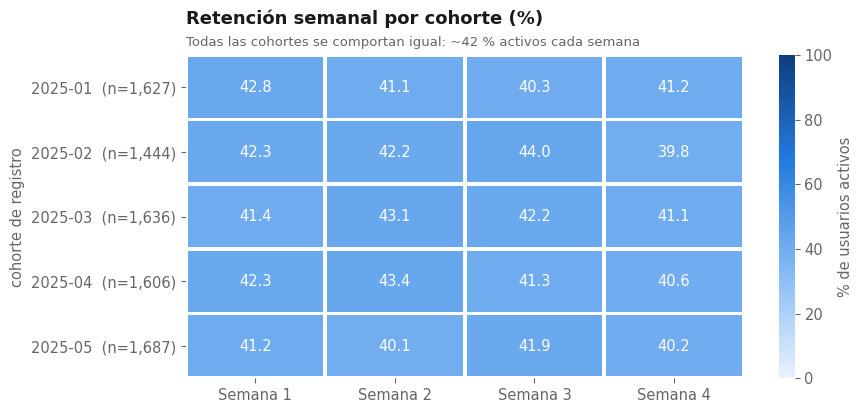

Retención promedio ponderada → semana 1: 42.0%, semana 3: 41.9%


In [48]:
#  mapa de calor de retención incluyendo la semana 4 (día 28)
query_retencion_extendida = '''
SELECT CAST(DATE_TRUNC('month', CAST(u.fecha_registro AS DATE)) AS DATE) AS cohorte,
       CAST(CEIL(a.dias_despues_registro / 7.0) AS INT)                   AS semana,
       COUNT(DISTINCT u.id_usuario)                                       AS usuarios,
       ROUND(100.0 * SUM(a.activo) / COUNT(DISTINCT u.id_usuario), 2)     AS retencion_pct
FROM users u
JOIN user_activity a ON a.id_usuario = u.id_usuario
GROUP BY 1, 2
ORDER BY 1, 2;
'''
ret = pd.read_sql(query_retencion_extendida, con=engine)
ret['cohorte'] = pd.to_datetime(ret['cohorte']).dt.strftime('%Y-%m')
mapa = ret.pivot(index='cohorte', columns='semana', values='retencion_pct')
mapa.columns = [f'Semana {s}' for s in mapa.columns]
n_cohorte = ret.groupby('cohorte')['usuarios'].max()
mapa.index = [f'{c}  (n={n_cohorte[c]:,})' for c in mapa.index]

fig, ax = plt.subplots(figsize=(9, 4.2))
sns.heatmap(mapa, annot=True, fmt='.1f', cmap=CMAP_AZUL, vmin=0, vmax=100, linewidths=2, linecolor='white',
            cbar_kws={'label': '% de usuarios activos'}, ax=ax)
ax.set_xlabel(''); ax.set_ylabel('cohorte de registro')
titulo(ax, 'Retención semanal por cohorte (%)', 'Todas las cohortes se comportan igual: ~42 % activos cada semana')
plt.show()
print(f'Retención promedio ponderada → semana 1: {cohorte_final["retenido_w1"].sum() / cohorte_final["clientes_iniciales"].sum():.1%}, '
      f'semana 3: {cohorte_final["retenido_w3"].sum() / cohorte_final["clientes_iniciales"].sum():.1%}')

###  ¿RappiPlus (plan *paid*) retiene mejor? ¿Y compra más?

El objetivo del servicio es **aumentar la frecuencia de compra y el valor por usuario**. La tabla `users` trae el `tipo_plan` (`free` / `paid`), así que se puede comparar a los suscriptores contra el resto en tres frentes: actividad (SQL), conversión del funnel (SQL) y compras reales (cruzando con `orders` limpio del Paso 1).

,semana_1,semana_2,semana_3,semana_4
tipo_plan,,,,
free,35.05,35.82,35.66,34.89
paid,62.40,59.89,60.14,57.48


tipo_plan,free,paid
semanas_activas,,
0,17.60,2.30
1,37.90,15.30
2,31.30,35.80
3,11.80,33.60
4,1.30,13.10


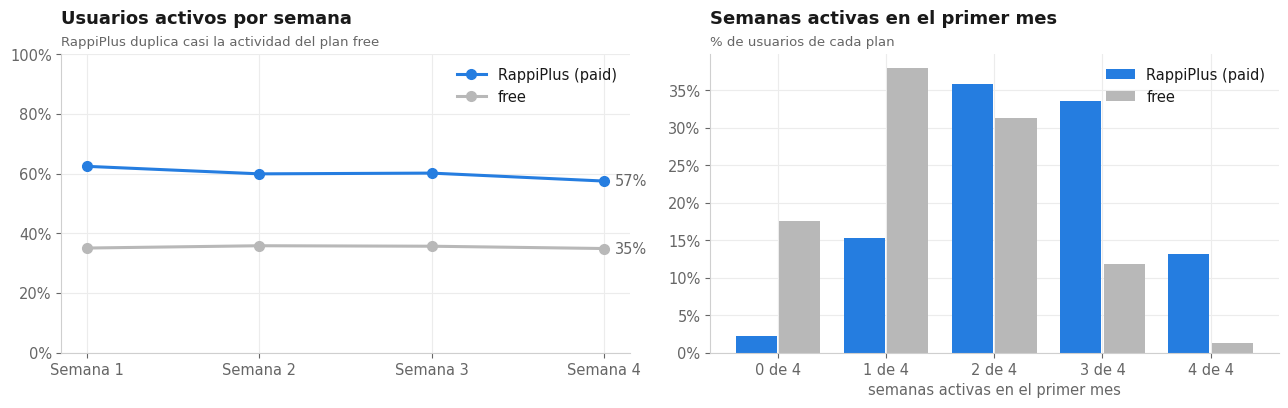

In [49]:
query_retencion_plan = '''
SELECT u.tipo_plan,
       CAST(CEIL(a.dias_despues_registro / 7.0) AS INT) AS semana,
       COUNT(DISTINCT u.id_usuario)                     AS usuarios,
       ROUND(100.0 * AVG(a.activo), 2)                  AS retencion_pct
FROM users u
JOIN user_activity a ON a.id_usuario = u.id_usuario
GROUP BY 1, 2
ORDER BY 1, 2;
'''
ret_plan = pd.read_sql(query_retencion_plan, con=engine)
tabla_ret_plan = ret_plan.pivot(index='tipo_plan', columns='semana', values='retencion_pct')
tabla_ret_plan.columns = [f'semana_{s}' for s in tabla_ret_plan.columns]
display(tabla_ret_plan)

query_semanas_activas = '''
WITH por_usuario AS (
    SELECT u.id_usuario, u.tipo_plan, CAST(SUM(a.activo) AS INT) AS semanas_activas
    FROM users u
    JOIN user_activity a ON a.id_usuario = u.id_usuario
    GROUP BY u.id_usuario, u.tipo_plan
)
SELECT tipo_plan, semanas_activas, COUNT(*) AS usuarios
FROM por_usuario
GROUP BY tipo_plan, semanas_activas
ORDER BY tipo_plan, semanas_activas;
'''
sem = pd.read_sql(query_semanas_activas, con=engine)
sem = sem.pivot(index='semanas_activas', columns='tipo_plan', values='usuarios')
sem_pct = sem / sem.sum() * 100
display(sem_pct.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
colores_plan = {'paid': AZUL, 'free': GRIS}
for plan in ['paid', 'free']:
    serie = tabla_ret_plan.loc[plan]
    axes[0].plot(range(1, len(serie) + 1), serie.values, marker='o', linewidth=2.2, markersize=7,
                 color=colores_plan[plan], label='RappiPlus (paid)' if plan == 'paid' else 'free')
    axes[0].annotate(f'{serie.values[-1]:.0f}%', (len(serie), serie.values[-1]), xytext=(8, 0),
                     textcoords='offset points', va='center', color=TEXTO_2)
axes[0].set_xticks(range(1, 5)); axes[0].set_xticklabels([f'Semana {s}' for s in range(1, 5)])
axes[0].set_ylim(0, 100); axes[0].yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
axes[0].legend(loc='upper right')
titulo(axes[0], 'Usuarios activos por semana', 'RappiPlus duplica casi la actividad del plan free')

x = np.arange(len(sem_pct))
axes[1].bar(x - 0.2, sem_pct['paid'], width=0.38, color=AZUL, label='RappiPlus (paid)')
axes[1].bar(x + 0.2, sem_pct['free'], width=0.38, color=GRIS, label='free')
axes[1].set_xticks(x); axes[1].set_xticklabels([f'{i} de 4' for i in sem_pct.index])
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
axes[1].set_xlabel('semanas activas en el primer mes')
axes[1].legend()
titulo(axes[1], 'Semanas activas en el primer mes', '% de usuarios de cada plan')
plt.tight_layout()
plt.show()

Pedidos sin usuario en la tabla users        : 0
Pedidos con fecha anterior al registro       : 41.7%  ⚠️


tipo_plan,free,paid,paid vs free
usuarios registrados,"5,968.00","2,032.00",-65.95
retención semana 1 %,35.05,62.40,78.03
retención semana 4 %,34.89,57.48,64.75
conversión visita → compra %,80.02,80.10,0.10
% de usuarios que compró,95.49,95.52,0.03
pedidos por comprador,3.27,3.22,-1.68
ticket promedio,385.59,386.64,0.27
revenue por comprador,"1,262.38","1,244.57",-1.41
profit bruto por comprador,758.83,750.43,-1.11


Pedidos por comprador paid vs free → p-value Mann-Whitney = 0.390


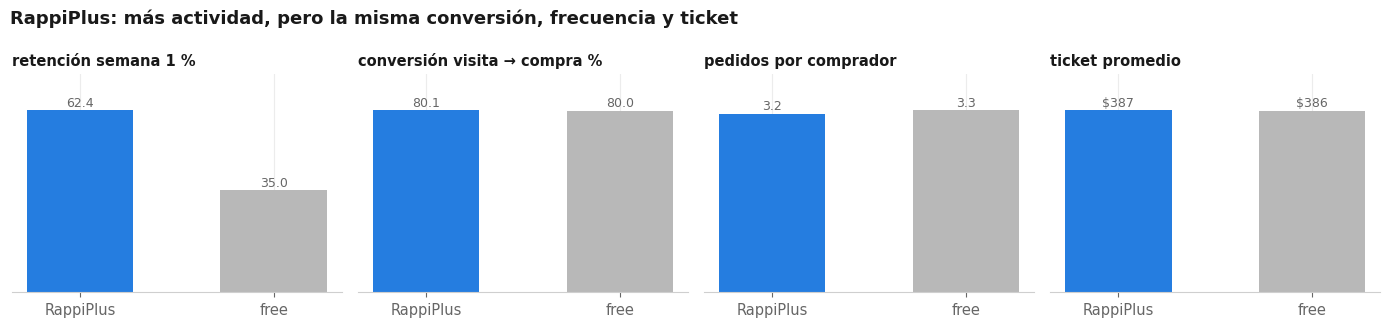

In [50]:
#  ¿los suscriptores convierten y compran más? (funnel por plan + pedidos reales)
query_funnel_plan = '''
SELECT u.tipo_plan, e.nombre_evento, COUNT(DISTINCT e.id_usuario) AS usuarios
FROM events e
JOIN users u ON u.id_usuario = e.id_usuario
GROUP BY 1, 2;
'''
fp = pd.read_sql(query_funnel_plan, con=engine).pivot(index='tipo_plan', columns='nombre_evento', values='usuarios')[orden_etapas]

usuarios_plan = users[['id_usuario', 'tipo_plan', 'fecha_registro']].copy()
usuarios_plan['fecha_registro'] = pd.to_datetime(usuarios_plan['fecha_registro'])
compras = ventas.merge(usuarios_plan, on='id_usuario', how='left', validate='many_to_one')
print('Pedidos sin usuario en la tabla users        :', compras['tipo_plan'].isna().sum())
print(f"Pedidos con fecha anterior al registro       : {(compras['fecha_hora_pedido'] < compras['fecha_registro']).mean():.1%}  ⚠️")

comparativo = pd.DataFrame({
    'usuarios registrados': usuarios_plan.groupby('tipo_plan').size(),
    'retención semana 1 %': tabla_ret_plan['semana_1'],
    'retención semana 4 %': tabla_ret_plan['semana_4'],
    'conversión visita → compra %': fp['purchase'] / fp['first_visit'] * 100,
    '% de usuarios que compró': compras.groupby('tipo_plan')['id_usuario'].nunique() / usuarios_plan.groupby('tipo_plan').size() * 100,
    'pedidos por comprador': compras.groupby('tipo_plan')['id_pedido'].count() / compras.groupby('tipo_plan')['id_usuario'].nunique(),
    'ticket promedio': compras.groupby('tipo_plan')['monto_total'].mean(),
    'revenue por comprador': compras.groupby('tipo_plan')['monto_total'].sum() / compras.groupby('tipo_plan')['id_usuario'].nunique(),
    'profit bruto por comprador': compras.groupby('tipo_plan')['profit'].sum() / compras.groupby('tipo_plan')['id_usuario'].nunique(),
}).T
comparativo['paid vs free'] = (comparativo['paid'] / comparativo['free'] - 1) * 100
display(comparativo.round(2))

# prueba de diferencia en pedidos por comprador (Mann-Whitney, no asume normalidad)
ped_x_user = compras.groupby(['tipo_plan', 'id_usuario'])['id_pedido'].count()
u_stat, p_pedidos = stats.mannwhitneyu(ped_x_user['paid'], ped_x_user['free'], alternative='two-sided')
print(f'Pedidos por comprador paid vs free → p-value Mann-Whitney = {p_pedidos:.3f}')

metricas = ['retención semana 1 %', 'conversión visita → compra %', 'pedidos por comprador', 'ticket promedio']
fig, axes = plt.subplots(1, 4, figsize=(14, 3.3))
for ax, m in zip(axes, metricas):
    vals = comparativo.loc[m, ['paid', 'free']]
    b = ax.bar(['RappiPlus', 'free'], vals.values, color=[AZUL, GRIS], width=0.55)
    etiquetar_barras(ax, b, vals.values, (lambda v: f'${v:,.0f}') if 'ticket' in m else (lambda v: f'{v:,.1f}'))
    ax.set_title(m, loc='left', fontsize=10.5)
    ax.set_ylim(0, vals.max() * 1.2); ax.set_yticks([])
    ax.spines['left'].set_visible(False)
fig.suptitle('RappiPlus: más actividad, pero la misma conversión, frecuencia y ticket', x=0.01, ha='left',
             fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

⚠️ **Limitación de datos:** ~42 % de los pedidos tiene fecha anterior al registro del usuario en `users`. Esto indica que `fecha_registro` probablemente corresponde a otro evento (p. ej. alta en RappiPlus o migración de cuentas) o que las fuentes no están sincronizadas. Por eso la comparación de compras se presenta como **asociación**, no como efecto causal del plan, y se recomienda validar con el equipo de datos la definición de `fecha_registro`.

💡 **Insight Paso 4 — ¿Los usuarios regresan?** **Cuatro de cada diez sí:** ~42 % de cada cohorte está activa en las semanas 1, 2 y 3 (y ~41 % en la semana 4). Las curvas son planas y casi idénticas entre cohortes (ene–may): la pérdida ocurre **antes de la primera semana** y después la base activa se mantiene estable; no hay deterioro ni mejora en el tiempo.

La diferencia está en el plan: **los suscriptores RappiPlus están activos ~60 % de las semanas contra ~35 % del plan free (1.7×)**, y solo 2 % de ellos nunca se activa en el primer mes (vs 18 % en free). Sin embargo, **no convierten más, no compran con más frecuencia ni gastan más por pedido** que los usuarios free. Es decir, la suscripción genera *engagement* pero todavía **no está cumpliendo su objetivo de negocio** (más compras y más valor por usuario). Recomendación: atar los beneficios de RappiPlus a la compra (envío gratis sobre un monto mínimo, cashback, precios exclusivos) y medir pedidos por suscriptor como KPI principal del programa.

---

## 🔹 Paso 5: Validar si los cambios generan impacto (test estadístico)

🎯 **Objetivo:** Evaluar si la modificación en la UI del checkout impacta la **tasa de conversión de compra**.

---

1. **Analizar el dataset** `experiment_checkout_ui.csv` para identificar la métrica principal **conversion**.
   - La métrica **conversion** es 1 si el usuario completó la compra, 0 si no.    
2. **Plantear la hipótesis estadística**     
3. **Aplicar el test estadístico adecuado** 
4. **Interpretar el resultado**  

---
Hipótesis estadística
   - **H₀ (Hipótesis nula):** la nueva UI del checkout **no cambia** la tasa de conversión de compra → p<sub>tratamiento</sub> = p<sub>control</sub>.
   - **H₁ (Hipótesis alternativa):** la tasa de conversión del grupo tratamiento **es distinta** a la del grupo control → p<sub>tratamiento</sub> ≠ p<sub>control</sub>. Se usa una prueba **bilateral** porque un rediseño también podría *empeorar* la conversión.

**Test estadístico:** prueba Z para la diferencia de dos proporciones independientes. La métrica (`convirtio` en el dataset) es binaria, los usuarios son independientes y cada grupo tiene ~5,000 usuarios con más de 10 conversiones y no conversiones, así que la aproximación normal es válida. Se confirma con una prueba χ² de independencia (equivalente).
**Nivel de significancia alpha:** 0.05

In [51]:
# Cargar y revisar el experimento
experimento = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/experiment_checkout_ui.csv')
experimento['timestamp'] = pd.to_datetime(experimento['timestamp'], format='%Y-%m-%d')
display(experimento.head())
display(perfil(experimento))
print('Usuarios duplicados   :', experimento['id_usuario'].duplicated().sum())
print('Valores de convirtio  :', sorted(experimento['convirtio'].unique()))
print('Periodo               :', experimento['timestamp'].min().date(), '→', experimento['timestamp'].max().date())
print('Usuarios por variante :', experimento['variante'].value_counts().to_dict())

#  Sample Ratio Mismatch — ¿la asignación 50/50 se respetó?
n_variante = experimento['variante'].value_counts()
_, p_srm = stats.chisquare(n_variante.values)
print(f'➕ Prueba SRM (χ² contra 50/50): p = {p_srm:.3f} →', 'asignación balanceada ✅' if p_srm > 0.01 else 'desbalance ⚠️')

#  balance de covariables — ¿los grupos son comparables?
for col in ['dispositivo', 'pais']:
    tabla = pd.crosstab(experimento['variante'], experimento[col])
    _, p_bal, _, _ = stats.chi2_contingency(tabla)
    print(f'➕ Balance por {col:<11}: p = {p_bal:.3f}', '✅' if p_bal > 0.05 else '⚠️')
    display((tabla.div(tabla.sum(axis=1), axis=0) * 100).round(1))

,id_usuario,variante,convirtio,dispositivo,pais,duracion_sesion,timestamp
0,exp_user_0,tratamiento,0,mobile,Argentina,114.41,2025-03-28
1,exp_user_1,tratamiento,0,desktop,Mexico,170.03,2025-01-15
2,exp_user_2,control,1,mobile,Colombia,140.21,2025-03-18
3,exp_user_3,tratamiento,0,mobile,Colombia,151.45,2025-06-03
4,exp_user_4,tratamiento,0,desktop,Mexico,299.96,2025-01-12


,tipo,nulos,% nulos,valores únicos
id_usuario,object,0,0.00,10000
variante,object,0,0.00,2
convirtio,int64,0,0.00,2
dispositivo,object,0,0.00,2
pais,object,0,0.00,3
duracion_sesion,float64,0,0.00,8446
timestamp,datetime64[ns],0,0.00,181


Usuarios duplicados   : 0
Valores de convirtio  : [0, 1]
Periodo               : 2025-01-01 → 2025-06-30
Usuarios por variante : {'tratamiento': 5035, 'control': 4965}
➕ Prueba SRM (χ² contra 50/50): p = 0.484 → asignación balanceada ✅
➕ Balance por dispositivo: p = 0.868 ✅


dispositivo,desktop,mobile
variante,,
control,50.50,49.50
tratamiento,50.30,49.70


➕ Balance por pais       : p = 0.843 ✅


pais,Argentina,Colombia,Mexico
variante,,,
control,33.40,32.90,33.80
tratamiento,33.00,32.70,34.30


In [52]:
# Tasa de conversión por variante y prueba Z de dos proporciones
alpha = 0.05
resumen_ab = experimento.groupby('variante').agg(usuarios=('id_usuario', 'count'), conversiones=('convirtio', 'sum'),
                                                 tasa_conversion=('convirtio', 'mean'))
resumen_ab['tasa_conversion %'] = resumen_ab['tasa_conversion'] * 100
display(resumen_ab)

conv = resumen_ab.loc[['tratamiento', 'control'], 'conversiones'].values
nobs = resumen_ab.loc[['tratamiento', 'control'], 'usuarios'].values
p_t, p_c = conv / nobs

z_stat, p_value = proportions_ztest(conv, nobs, alternative='two-sided')
ic_bajo, ic_alto = confint_proportions_2indep(conv[0], nobs[0], conv[1], nobs[1], method='wald', alpha=alpha)
chi2_stat, p_chi2, _, _ = stats.chi2_contingency(pd.crosstab(experimento['variante'], experimento['convirtio']), correction=False)

print(f'Conversión control      : {p_c:.2%}')
print(f'Conversión tratamiento  : {p_t:.2%}')
print(f'Diferencia absoluta     : {(p_t - p_c) * 100:+.2f} pp  (IC 95 %: {ic_bajo * 100:+.2f} a {ic_alto * 100:+.2f} pp)')
print(f'Lift relativo           : {p_t / p_c - 1:+.1%}')
print(f'Estadístico Z = {z_stat:.3f} | p-value = {p_value:.4f}  (confirmación χ²: p = {p_chi2:.4f})')
print()
if p_value < alpha:
    print(f'➡ p-value < {alpha}: se RECHAZA H₀. La nueva UI cambia la conversión de forma estadísticamente significativa.')
else:
    print(f'➡ p-value ≥ {alpha}: NO se rechaza H₀. No hay evidencia suficiente de que la nueva UI cambie la conversión.')

,usuarios,conversiones,tasa_conversion,tasa_conversion %
variante,,,,
control,4965,779,0.16,15.69
tratamiento,5035,820,0.16,16.29


Conversión control      : 15.69%
Conversión tratamiento  : 16.29%
Diferencia absoluta     : +0.60 pp  (IC 95 %: -0.84 a +2.03 pp)
Lift relativo           : +3.8%
Estadístico Z = 0.813 | p-value = 0.4161  (confirmación χ²: p = 0.4161)

➡ p-value ≥ 0.05: NO se rechaza H₀. No hay evidencia suficiente de que la nueva UI cambie la conversión.


In [53]:
#  análisis de potencia — ¿el experimento podía detectar un efecto de este tamaño?
potencia_analisis = NormalIndPower()
h_observado = proportion_effectsize(p_t, p_c)          # tamaño de efecto de Cohen (h)
potencia = potencia_analisis.solve_power(effect_size=h_observado, nobs1=nobs[0], ratio=nobs[1] / nobs[0], alpha=alpha)
n_necesario = potencia_analisis.solve_power(effect_size=h_observado, power=0.8, alpha=alpha, ratio=1)
h_mde = potencia_analisis.solve_power(nobs1=nobs[0], ratio=nobs[1] / nobs[0], alpha=alpha, power=0.8)
p_mde = np.sin(np.arcsin(np.sqrt(p_c)) + h_mde / 2) ** 2

print(f"Tamaño de efecto observado (Cohen's h)     : {h_observado:.4f}  → efecto muy pequeño")
print(f'Potencia real del test para ese efecto      : {potencia:.1%}  (lo recomendable es ≥ 80 %)')
print(f'Efecto mínimo detectable (MDE, 80 % potencia): {(p_mde - p_c) * 100:.2f} pp  (de {p_c:.1%} a {p_mde:.1%})')
print(f'Usuarios por grupo para detectar +{(p_t - p_c) * 100:.2f} pp: {n_necesario:,.0f}  (hoy hay ~{nobs.mean():,.0f})')

Tamaño de efecto observado (Cohen's h)     : 0.0163  → efecto muy pequeño
Potencia real del test para ese efecto      : 12.9%  (lo recomendable es ≥ 80 %)
Efecto mínimo detectable (MDE, 80 % potencia): 2.09 pp  (de 15.7% a 17.8%)
Usuarios por grupo para detectar +0.60 pp: 59,319  (hoy hay ~5,000)


IC 95 % bootstrap de la diferencia: -0.84 a +2.04 pp (incluye el 0)
Probabilidad bayesiana de que tratamiento > control: 79.1% (umbral habitual para lanzar: ≥ 95 %)


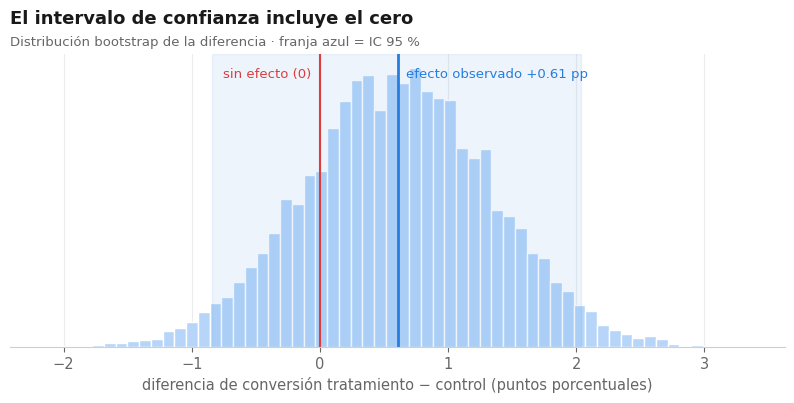

In [54]:
#  bootstrap (10,000 remuestreos) y probabilidad bayesiana de que el tratamiento sea mejor
rng = np.random.default_rng(42)
ctrl = experimento.loc[experimento['variante'] == 'control', 'convirtio'].values
trat = experimento.loc[experimento['variante'] == 'tratamiento', 'convirtio'].values
dif_boot = np.array([rng.choice(trat, trat.size).mean() - rng.choice(ctrl, ctrl.size).mean() for _ in range(10000)]) * 100
ic_boot = np.percentile(dif_boot, [2.5, 97.5])

post_t = rng.beta(1 + trat.sum(), 1 + trat.size - trat.sum(), 200000)   # prior uniforme Beta(1,1)
post_c = rng.beta(1 + ctrl.sum(), 1 + ctrl.size - ctrl.sum(), 200000)
prob_mejor = (post_t > post_c).mean()
print(f'IC 95 % bootstrap de la diferencia: {ic_boot[0]:+.2f} a {ic_boot[1]:+.2f} pp (incluye el 0)')
print(f'Probabilidad bayesiana de que tratamiento > control: {prob_mejor:.1%} (umbral habitual para lanzar: ≥ 95 %)')

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(dif_boot, bins=60, color='#b6d5f8', edgecolor='white')
ax.axvspan(ic_boot[0], ic_boot[1], color=AZUL, alpha=0.08)
ax.axvline(0, color=ROJO, linewidth=1.5)
ax.axvline(dif_boot.mean(), color=AZUL, linewidth=2)
ax.annotate('sin efecto (0)', (0, ax.get_ylim()[1] * 0.92), xytext=(-6, 0), textcoords='offset points', ha='right',
            color=ROJO, fontsize=9.5)
ax.annotate(f'efecto observado {dif_boot.mean():+.2f} pp', (dif_boot.mean(), ax.get_ylim()[1] * 0.92), xytext=(6, 0),
            textcoords='offset points', color=AZUL, fontsize=9.5)
ax.set_xlabel('diferencia de conversión tratamiento − control (puntos porcentuales)')
ax.set_yticks([]); ax.spines['left'].set_visible(False)
titulo(ax, 'El intervalo de confianza incluye el cero', 'Distribución bootstrap de la diferencia · franja azul = IC 95 %')
plt.show()

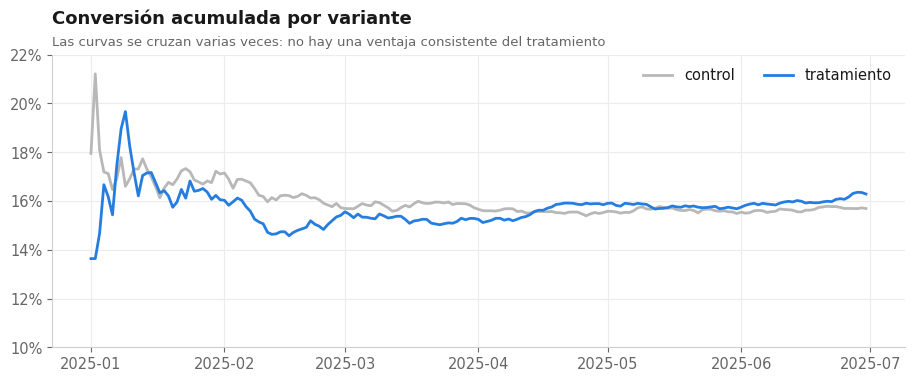

In [55]:
#  conversión acumulada día a día (estabilidad del resultado / efecto novedad)
diario = experimento.groupby(['timestamp', 'variante'])['convirtio'].agg(['sum', 'count']).unstack()
acumulada = diario['sum'].cumsum() / diario['count'].cumsum() * 100

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(acumulada.index, acumulada['control'], color=GRIS, linewidth=2, label='control')
ax.plot(acumulada.index, acumulada['tratamiento'], color=AZUL, linewidth=2, label='tratamiento')
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_ylim(10, 22)
ax.legend(loc='upper right', ncol=2)
titulo(ax, 'Conversión acumulada por variante', 'Las curvas se cruzan varias veces: no hay una ventaja consistente del tratamiento')
plt.show()

,segmento,control %,tratamiento %,IC bajo,IC alto,p_value,diferencia pp,p_bonferroni,significativo
0,dispositivo: desktop,18.38,18.19,-2.32,1.95,0.86,-0.19,1.00,False
1,dispositivo: mobile,12.94,14.35,-0.50,3.32,0.15,1.41,0.74,False
2,pais: Argentina,16.18,16.44,-2.26,2.77,0.84,0.25,1.00,False
3,pais: Colombia,15.87,15.49,-2.87,2.11,0.77,-0.38,1.00,False
4,pais: Mexico,15.03,16.90,-0.59,4.33,0.14,1.87,0.68,False


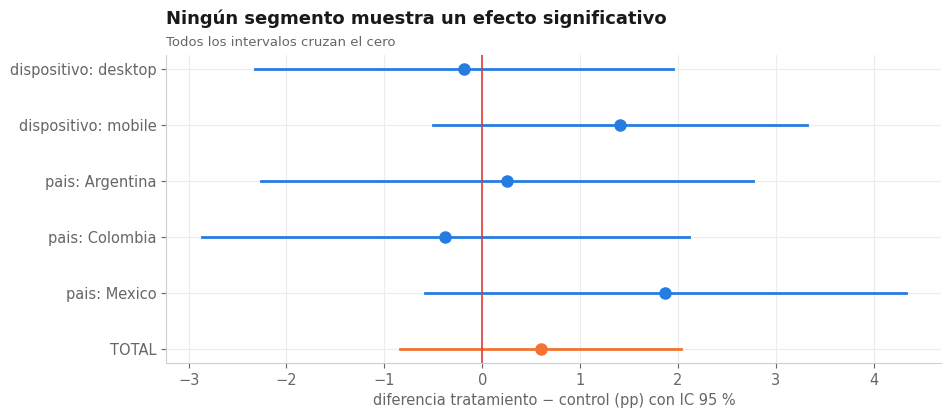

In [56]:
#  efecto por segmento (con corrección de Bonferroni por comparaciones múltiples)
filas = []
for col in ['dispositivo', 'pais']:
    for segmento, d in experimento.groupby(col):
        r = d.groupby('variante')['convirtio'].agg(['sum', 'count'])
        _, p_seg = proportions_ztest(r.loc[['tratamiento', 'control'], 'sum'].values, r.loc[['tratamiento', 'control'], 'count'].values)
        lo, hi = confint_proportions_2indep(r.loc['tratamiento', 'sum'], r.loc['tratamiento', 'count'],
                                            r.loc['control', 'sum'], r.loc['control', 'count'], method='wald')
        filas.append({'segmento': f'{col}: {segmento}', 'control %': r.loc['control', 'sum'] / r.loc['control', 'count'] * 100,
                      'tratamiento %': r.loc['tratamiento', 'sum'] / r.loc['tratamiento', 'count'] * 100,
                      'IC bajo': lo * 100, 'IC alto': hi * 100, 'p_value': p_seg})
seg_ab = pd.DataFrame(filas)
seg_ab['diferencia pp'] = seg_ab['tratamiento %'] - seg_ab['control %']
seg_ab['p_bonferroni'] = (seg_ab['p_value'] * len(seg_ab)).clip(upper=1)
seg_ab['significativo'] = seg_ab['p_bonferroni'] < alpha
display(seg_ab.round(3))

total = pd.DataFrame([{'segmento': 'TOTAL', 'diferencia pp': (p_t - p_c) * 100, 'IC bajo': ic_bajo * 100, 'IC alto': ic_alto * 100}])
forest = pd.concat([seg_ab, total], ignore_index=True).iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 4))
for i, fila in forest.iterrows():
    color = NARANJA if fila['segmento'] == 'TOTAL' else AZUL
    ax.plot([fila['IC bajo'], fila['IC alto']], [i, i], color=color, linewidth=2)
    ax.plot(fila['diferencia pp'], i, 'o', color=color, markersize=8)
ax.axvline(0, color=ROJO, linewidth=1.2)
ax.set_yticks(range(len(forest))); ax.set_yticklabels(forest['segmento'])
ax.set_xlabel('diferencia tratamiento − control (pp) con IC 95 %')
titulo(ax, 'Ningún segmento muestra un efecto significativo', 'Todos los intervalos cruzan el cero')
plt.show()

In [57]:
#  métrica de control (guardrail) — ¿la nueva UI cambió la duración de la sesión?
dur = experimento.groupby('variante')['duracion_sesion'].describe()
display(dur)
_, p_dur_t = stats.ttest_ind(experimento.loc[experimento['variante'] == 'tratamiento', 'duracion_sesion'],
                             experimento.loc[experimento['variante'] == 'control', 'duracion_sesion'], equal_var=False)
_, p_dur_mw = stats.mannwhitneyu(experimento.loc[experimento['variante'] == 'tratamiento', 'duracion_sesion'],
                                 experimento.loc[experimento['variante'] == 'control', 'duracion_sesion'], alternative='two-sided')
print(f'Duración media: control {dur.loc["control", "mean"]:.1f}s vs tratamiento {dur.loc["tratamiento", "mean"]:.1f}s '
      f'→ Welch t-test p = {p_dur_t:.3f} | Mann-Whitney p = {p_dur_mw:.3f}')

,count,mean,std,min,25%,50%,75%,max
variante,,,,,,,,
control,"4,965.00",161.04,81.47,20.01,91.03,161.28,230.96,300.00
tratamiento,"5,035.00",158.70,80.68,20.01,88.41,158.07,227.92,299.96


Duración media: control 161.0s vs tratamiento 158.7s → Welch t-test p = 0.148 | Mann-Whitney p = 0.147


💡 **Interpretación y recomendación — ¿Los cambios generan impacto?**

- La conversión pasó de **15.69 % (control) a 16.29 % (tratamiento)**: +0.60 pp (+3.8 % relativo). Con **p-value ≈ 0.42 > 0.05 no se rechaza H₀**: la diferencia es compatible con el azar. El intervalo de confianza al 95 % va de −0.84 a +2.03 pp, así que la nueva UI podría ayudar un poco, no hacer nada o incluso restar.
- ➕ El experimento estaba **sub-dimensionado** para un efecto así: con ~5,000 usuarios por grupo tenía apenas **13 % de potencia** para un efecto de +0.6 pp y solo podía detectar mejoras de ~2.1 pp o más. Para confirmar +0.6 pp harían falta **~59,000 usuarios por grupo**.
- ➕ El resultado es robusto: la asignación fue balanceada (sin SRM), los grupos son comparables, el bootstrap y el enfoque bayesiano coinciden (P(tratamiento > control) ≈ 79 %, lejos del 95 % habitual), ningún segmento muestra un efecto significativo y la duración de sesión (guardrail) no cambió.

**Recomendación:** **no lanzar la nueva UI como una "mejora probada".** Si su costo de mantenimiento es bajo y no daña ninguna métrica, puede adoptarse por razones de diseño, pero sin atribuirle crecimiento. El siguiente experimento debe atacar el punto donde el funnel (Paso 3) pierde más usuarios —**el paso de registro del pago** (13 % de abandono)— con una métrica primaria específica (`begin_checkout → add_payment_info`) y un tamaño de muestra calculado de antemano.

---

## 🔹 Paso 6: Comunicar los resultados (Dashboard en BI)

🎯 **Objetivo**:  
Crear un dashboard que muestre de manera clara y visual los resultados del análisis de ventas, costos, marketing y conversión. 

Se usarán los CSVs limpios del Paso 1:

- `orders_clean.csv`  
- `catalog_clean.csv`  
- `marketing_clean.csv`

---

1️⃣ Preparación de los datos
1. Cargar los CSVs en Power BI o Tableau.
2. Revisar relaciones:
   - `orders.nombre_producto` → `catalog.nombre_producto`
   - `orders.fecha_pedido` → tabla de fechas (crear calendario para análisis temporal)
   - `orders.fecha_pedido` → `dim_fecha.date`
3. Crear columnas calculadas necesarias
4. Crear tabla de fechas para poder calcular comparaciones YTD, YoY o períodos anteriores (`Previous Year`, `Previous Month`).

---

2️⃣ Dashboard 1: Overview Ejecutivo
**KPIs principales a mostrar:**
- Revenue total
- Profit total
- Gasto total en marketing
- Ticket promedio
- Cantidad promedio de productos por orden

**Visualizaciones sugeridas:**
- Tarjetas KPI para revenue, profit y gasto marketing
- Gráfico de líneas: evolución mensual de revenue o profit
- Gráfico de líneas YTD
- Gráfico de barras: revenue y profit por producto o categoría

---

 3️⃣ Dashboard 2: Detalle / Drill-through  
**Objetivo:** Permitir explorar los datos desde el KPI general hasta cada orden o producto.

**Visualizaciones sugeridas:**
- Tabla detallada de órdenes con:
  - producto, cantidad, revenue, cost, profit
  - color condicional (profit negativo en rojo, positivo en verde)
- Gráfico de barras por producto con medida `cantidad vendida`
- Drill-through: seleccionar un producto y ver todos los pedidos relacionados
- Filtros por fecha, categoría de producto, etc

### ➕ Implementación del dashboard (Power BI)

**Entregable:** proyecto `RappiPlus.pbip` construido en Power BI Desktop y guardado como `RappiPlus_Dashboard.pbix`, con los CSV limpios del Paso 1 como fuente (parámetro `RutaDatos`).

**Modelo en estrella** (relaciones uno a muchos, filtro en una sola dirección; `catalog` tiene un registro por producto, así que la unión no duplica pedidos):

| Tabla | Rol | Origen |
|---|---|---|
| `orders` | Hechos | `orders_clean.csv` + columnas calculadas `costo_unitario` (`RELATED`), `costo_total`, `profit`, `resultado` (Ganancia/Pérdida) |
| `catalog` | Dimensión producto | `catalog_clean.csv` → `orders[nombre_producto]` |
| `dim_fecha` | Calendario DAX (`CALENDAR` + `ADDCOLUMNS`), marcada como tabla de fechas | → `orders[fecha_hora_pedido]` |
| ➕ `marketing` | Hechos | `marketing_clean.csv` → `dim_fecha`, `dim_pais`, `dim_canal` (para el KPI de gasto y el ROI) |
| ➕ `dim_pais`, `dim_canal` | Dimensiones compartidas | Evitan que filtrar por país o canal deje fuera el gasto de marketing |
| ➕ `funnel_resumen`, `retencion_*`, `ab_test_resumen` | Resultados de SQL y del test | Exportados en la celda siguiente |

**Medidas DAX (36):** `Revenue`, `Costo Total`, `Profit`, `Margen %`, `Ticket Promedio`, `Productos por Orden`, `Unidades`, `Revenue YTD` / `Profit YTD` (`TOTALYTD`), `Revenue Mes Anterior` (`PREVIOUSMONTH`), `Var % YoY` (`SAMEPERIODLASTYEAR`), `% Pedidos con Pérdida`, `Color Profit` (formato condicional) y ➕ `Gasto Marketing`, `Profit Neto`, `ROAS`, `ROI Marketing`, entre otras.

**Páginas**
1. **Overview ejecutivo:** KPIs (revenue, profit, margen, gasto en marketing, ticket promedio, productos por orden), evolución mensual, acumulado YTD, revenue y profit por producto, margen % por producto (rojo si es negativo). Filtros: mes, país y categoría.
2. **Detalle de pedidos:** tabla de órdenes con producto, cantidad, revenue, costo y profit (rojo/verde), cantidad vendida por producto y filtros por mes, país, categoría y producto.
3. **Detalle de producto (drill-through):** clic derecho sobre un producto → *Obtener detalles* → KPIs, evolución mensual y todos sus pedidos.
4. ➕ **Marketing:** gasto, profit neto, ROAS y ROI por canal y país.
5. ➕ **Funnel, retención y A/B:** resultados de los Pasos 3, 4 y 5 en el mismo tablero.

In [58]:
# ➕ Extra: exportar los resultados de SQL y del test A/B para la página "Funnel, retención y A/B" del dashboard
conversion.to_csv('funnel_resumen.csv', index=False)
ret.to_csv('retencion_cohortes.csv', index=False)
ret_plan.to_csv('retencion_plan.csv', index=False)
resumen_ab.reset_index().to_csv('ab_test_resumen.csv', index=False)
print('Exportados: funnel_resumen.csv, retencion_cohortes.csv, retencion_plan.csv, ab_test_resumen.csv')

Exportados: funnel_resumen.csv, retencion_cohortes.csv, retencion_plan.csv, ab_test_resumen.csv


---

## ➕ 📌 Conclusiones y recomendaciones

| Pregunta del negocio | Respuesta | Evidencia clave |
|---|---|---|
| **¿Podemos confiar en los datos?** | Sí, tras la limpieza | 10 pedidos con cantidades de 10,000+ inflaban el revenue 5.4×; se eliminó solo el 0.77 % de las filas |
| **¿Estamos ganando dinero?** | Sí | Revenue $9.61M · margen bruto 60.2 % · profit neto después de marketing $2.91M (30.3 %) |
| **¿Dónde se pierden los usuarios?** | En el registro del pago | `begin_checkout → add_payment_info` pierde 958 usuarios (13.3 %); conversión final 80.0 % |
| **¿Los usuarios regresan?** | 4 de cada 10, cada semana | Retención estable ~42 % (sem. 1–3); RappiPlus ~60 % vs free ~35 % |
| **¿Los cambios generan impacto?** | No se demostró | +0.60 pp, p ≈ 0.42; el test solo podía detectar efectos ≥ ~2.1 pp (potencia 13 %) |

**Recomendaciones accionables (priorizadas por impacto)**

1. **Fijar un precio mínimo por producto ligado al costo.** Hoy los precios van de $20 a $500 sin relación con el costo: 18 % de los pedidos se vende con pérdida ($666K en el semestre) y Laptop-Gaming-16GB es el único producto con profit negativo. Es la palanca de rentabilidad más grande y no requiere vender más.
2. **Rediseñar y volver a testear el paso de pago**, no la UI completa del checkout: es donde está el 13 % de abandono. Definir antes del test la métrica (`begin_checkout → add_payment_info`) y el tamaño de muestra.
3. **Reasignar presupuesto de marketing hacia paid_search** (ROI 1.13 vs ~0.95 de social y organic) y revisar *social* en Argentina (ROI 0.83, el más bajo).
4. **Conectar los beneficios de RappiPlus con la compra.** Los suscriptores son 1.7× más activos pero compran igual que los usuarios free; sin un incentivo ligado al pedido la suscripción no cumple su objetivo de aumentar frecuencia y ticket.
5. **Gobierno de datos:** validar en el origen las cantidades (bloquear valores fuera de rango), unificar catálogos de país/categoría, corregir los huecos de tracking del funnel y aclarar la definición de `fecha_registro` (42 % de los pedidos es anterior a ella).

## 🚀 Entrega Final

Comparte el acceso a tu Dashboard para revisión.   
Puedes entregar el Dashboard utilizando **Power BI o Tableau**.

Incluye **uno de los siguientes**:

- 🔗 Link público del dashboard publicado en **Power BI Service o Tableau Public / Tableau Cloud**
- 🔗 Link de **Google Drive o OneDrive** con el archivo del proyecto (`.pbix`) y los 3 csvs limpios.


### 📎 Enlace del Dashboard